# Minería de Datos
## Análisis de factores asociados al bajo rendimiento académico

## presentado por **Laura sanchez y jhon edison jordan**

**Pregunta de negocio:** ¿Qué factores académicos, familiares y de comportamiento se relacionan con el bajo rendimiento en Matemáticas y Portugués, y qué diferencias generales aparecen entre las dos asignaturas?

**Alcance del proyecto:** para este trabajo utilicé los dos archivos del conjunto *Student Performance*: `student-mat.csv` (Matemáticas) y `student-por.csv` (Portugués). Ambos contienen variables académicas, familiares y de comportamiento. Los analicé por separado y luego comparé sus resultados generales.

**Ajuste de la pregunta inicial:** la idea original estaba relacionada con la participación en foros académicos. Al revisar las columnas disponibles, comprobé que estos archivos no miden participación en foros; por eso adapté el análisis al rendimiento académico, que sí está representado por las calificaciones G1, G2 y G3.

**Criterio utilizado:** para poder comparar las dos asignaturas, definí bajo rendimiento como una calificación final `G3 < 10`, en una escala de 0 a 20. Es un umbral operativo para este ejercicio y no reemplaza el criterio oficial de una institución.




## Resumen ejecutivo –

Este proyecto empezó con una pregunta relacionada con la identificación temprana de estudiantes que podrían necesitar acompañamiento académico. Cuando revisé los datos, encontré que no había variables sobre participación en foros. En lugar de forzar una respuesta que las bases no podían dar, ajusté el problema al rendimiento académico y trabajé con las dos asignaturas disponibles: Matemáticas y Portugués.

Utilicé los archivos `student-mat.csv` y `student-por.csv`, pertenecientes al conjunto *Student Performance* del repositorio UCI. El primero contiene **395 registros y 33 variables**; el segundo, **649 registros y 33 variables**. Los procesé de forma independiente. Aunque comparten nombres de columnas, no tienen una identificación personal común que permita emparejar estudiantes con seguridad, así que las comparaciones se hacen a nivel general y no como si fueran observaciones pareadas.

Para mantener un criterio comparable, consideré bajo rendimiento una nota final `G3 < 10` sobre 20. En Matemáticas, la media de G3 fue **10,42** y el **32,91 %** de los registros quedó por debajo del umbral. En Portugués, la media fue **11,91** y el porcentaje de bajo rendimiento fue **15,41 %**. Estas diferencias describen las dos muestras; no demuestran que una asignatura sea más fácil ni que las características de una materia causen el resultado de la otra.

En ambas bases revisé tipos, datos faltantes, duplicados, rangos y valores atípicos. No encontré valores nulos ni filas duplicadas completas. El método IQR marcó observaciones con ausencias altas en ambas asignaturas y también notas bajas atípicas en Portugués. Como esos registros están dentro de los rangos válidos, los conservé marcados en vez de eliminarlos sin evidencia.

Después apliqué el mismo recorrido técnico por separado: preparación de variables, segmentación, clasificación y detección de anomalías. Para el árbol de decisión, el accuracy de prueba fue **90,8 % en Matemáticas** y **93,8 % en Portugués**. Sin embargo, el F1 de la clase de bajo rendimiento fue **0,867** y **0,786**, respectivamente. Por eso también revisé precisión, recall y matriz de confusión; el accuracy por sí solo no cuenta toda la historia.

En la segmentación, el análisis con K-means seleccionó preliminarmente **4 grupos para Matemáticas** y **3 para Portugués**, usando ausencias y G2. Con Isolation Forest, el escenario de `contamination=10 %` marcó **39 registros de Matemáticas** y **65 de Portugués**. Esas marcas no son errores confirmados: son combinaciones poco frecuentes que merecen una revisión contextual.

En conjunto, el proyecto muestra cómo se pueden explorar dos bases relacionadas, comparar patrones generales y construir modelos iniciales para apoyar el seguimiento académico. No pretende reemplazar el criterio docente. Para pensar en un uso real, sería necesario validar los modelos con datos de otros periodos, comprobar la calidad de los registros y revisar cada situación con una persona responsable.


## Preparación y carga de los datos

Sube los dos archivos: `student-mat.csv` y `student-por.csv`. También se aceptan nombres descargados como `student-mat(5).csv` y `student-por(5).csv`. Se guardan en dos dataframes independientes; no se hace un cruce fila a fila porque no hay un identificador personal común documentado.


In [1]:
from pathlib import Path
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# En Google Colab se abre el selector para subir los dos CSV.
# Fuera de Colab, el código también busca los archivos en la carpeta actual.
try:
    from google.colab import files
    uploaded = files.upload()
except ImportError:
    uploaded = {}


def localizar_csv(prefijo, archivos_subidos):
    candidatos = [
        nombre for nombre in archivos_subidos.keys()
        if nombre.lower().startswith(prefijo) and nombre.lower().endswith(".csv")
    ]
    if not candidatos:
        candidatos = [
            p.name for p in Path(".").glob(f"{prefijo}*.csv")
        ]
    if not candidatos:
        raise FileNotFoundError(
            f"No encontré un archivo que comience por {prefijo}. Sube el CSV correspondiente."
        )
    exacto = next((n for n in candidatos if n.lower() == f"{prefijo}.csv"), None)
    if exacto:
        return exacto

    # Si hay varias copias numeradas, se prefiere la versión con número más reciente.
    def version_archivo(nombre):
        coincidencia = re.search(r"\((\d+)\)", nombre)
        return int(coincidencia.group(1)) if coincidencia else -1

    return sorted(candidatos, key=version_archivo, reverse=True)[0]


archivo_mat = localizar_csv("student-mat", uploaded)
archivo_por = localizar_csv("student-por", uploaded)

mat = pd.read_csv(archivo_mat, sep=";")
por = pd.read_csv(archivo_por, sep=";")

# Se renombran las columnas para dejar claro a qué asignatura pertenece cada dato.
datos = mat.add_suffix("_mat").copy()
datos_por = por.add_suffix("_por").copy()

print("Archivo de Matemáticas:", archivo_mat, mat.shape)
print("Archivo de Portugués:", archivo_por, por.shape)
print("Las bases se analizarán por separado; no se emparejan filas entre asignaturas.")

print("\nPrimeros registros de Matemáticas:")
display(datos.head())
print("\nPrimeros registros de Portugués:")
display(datos_por.head())


Saving student-mat.csv to student-mat.csv
Saving student-por.csv to student-por.csv
Archivo de Matemáticas: student-mat.csv (395, 33)
Archivo de Portugués: student-por.csv (649, 33)
Las bases se analizarán por separado; no se emparejan filas entre asignaturas.

Primeros registros de Matemáticas:


,school_mat,sex_mat,age_mat,address_mat,famsize_mat,Pstatus_mat,Medu_mat,Fedu_mat,Mjob_mat,Fjob_mat,...,famrel_mat,freetime_mat,goout_mat,Dalc_mat,Walc_mat,health_mat,absences_mat,G1_mat,G2_mat,G3_mat
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10



Primeros registros de Portugués:


,school_por,sex_por,age_por,address_por,famsize_por,Pstatus_por,Medu_por,Fedu_por,Mjob_por,Fjob_por,...,famrel_por,freetime_por,goout_por,Dalc_por,Walc_por,health_por,absences_por,G1_por,G2_por,G3_por
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


##  Calidad de datos –

En esta parte revisé la estructura de la base antes de analizarla: tipos de datos, valores faltantes, registros repetidos y rangos válidos. También busqué valores atípicos. La idea fue conservar la información original y hacer cambios solo cuando hubiera una razón clara para hacerlo.

La misma revisión se repite en una sección posterior para el archivo de Portugués.


In [2]:
# Variables numéricas del conjunto de Matemáticas
variables_numericas = [
    "age_mat", "Medu_mat", "Fedu_mat", "traveltime_mat",
    "studytime_mat", "failures_mat", "famrel_mat", "freetime_mat",
    "goout_mat", "Dalc_mat", "Walc_mat", "health_mat",
    "absences_mat", "G1_mat", "G2_mat", "G3_mat"
]

columnas_convertidas = []
for columna in variables_numericas:
    tipo_anterior = datos[columna].dtype
    datos[columna] = pd.to_numeric(datos[columna], errors="coerce")
    tipo_actual = datos[columna].dtype
    if tipo_actual != tipo_anterior:
        columnas_convertidas.append((columna, str(tipo_anterior), str(tipo_actual)))

print("Columnas cuyo tipo cambió:")
if columnas_convertidas:
    display(pd.DataFrame(
        columnas_convertidas,
        columns=["Columna", "Tipo anterior", "Tipo actual"]
    ))
else:
    print("No fue necesario cambiar tipos: las variables numéricas ya estaban en formato numérico.")

print("\nINFORMACIÓN GENERAL")
datos.info()

print("\nTIPOS DE DATOS")
display(datos.dtypes.to_frame("tipo"))

print("\nVALORES NULOS POR COLUMNA")
display(datos.isnull().sum().to_frame("valores_nulos"))
print("Total de valores nulos:", int(datos.isnull().sum().sum()))

print("\nREGISTROS DUPLICADOS COMPLETOS:", int(datos.duplicated().sum()))

print("\nESTADÍSTICAS DESCRIPTIVAS")
display(datos[variables_numericas].describe())

Columnas cuyo tipo cambió:
No fue necesario cambiar tipos: las variables numéricas ya estaban en formato numérico.

INFORMACIÓN GENERAL
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   school_mat      395 non-null    object
 1   sex_mat         395 non-null    object
 2   age_mat         395 non-null    int64 
 3   address_mat     395 non-null    object
 4   famsize_mat     395 non-null    object
 5   Pstatus_mat     395 non-null    object
 6   Medu_mat        395 non-null    int64 
 7   Fedu_mat        395 non-null    int64 
 8   Mjob_mat        395 non-null    object
 9   Fjob_mat        395 non-null    object
 10  reason_mat      395 non-null    object
 11  guardian_mat    395 non-null    object
 12  traveltime_mat  395 non-null    int64 
 13  studytime_mat   395 non-null    int64 
 14  failures_mat    395 non-null    int64 
 15  school

,tipo
school_mat,object
sex_mat,object
age_mat,int64
address_mat,object
famsize_mat,object
Pstatus_mat,object
Medu_mat,int64
Fedu_mat,int64
Mjob_mat,object
Fjob_mat,object



VALORES NULOS POR COLUMNA


,valores_nulos
school_mat,0
sex_mat,0
age_mat,0
address_mat,0
famsize_mat,0
Pstatus_mat,0
Medu_mat,0
Fedu_mat,0
Mjob_mat,0
Fjob_mat,0


Total de valores nulos: 0

REGISTROS DUPLICADOS COMPLETOS: 0

ESTADÍSTICAS DESCRIPTIVAS


,age_mat,Medu_mat,Fedu_mat,traveltime_mat,studytime_mat,failures_mat,famrel_mat,freetime_mat,goout_mat,Dalc_mat,Walc_mat,health_mat,absences_mat,G1_mat,G2_mat,G3_mat
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


### Validación de rangos y consistencias

Antes de revisar los valores atípicos, comprobé que las notas `G1`, `G2` y `G3` estuvieran entre 0 y 20, y que las ausencias estuvieran entre 0 y 93, de acuerdo con la documentación del conjunto. No se encontraron registros fuera de esos intervalos. Si apareciera alguno, lo correcto sería revisarlo con la fuente original antes de corregirlo o excluirlo.


In [3]:
# Revisar notas fuera del rango documentado (0 a 20)
columnas_notas = ["G1_mat", "G2_mat", "G3_mat"]
mascara_notas_invalidas = datos[columnas_notas].lt(0).any(axis=1) | datos[columnas_notas].gt(20).any(axis=1)
notas_fuera_rango = datos.loc[mascara_notas_invalidas, columnas_notas]

# Revisar ausencias fuera del rango documentado (0 a 93)
mascara_ausencias_invalidas = (datos["absences_mat"] < 0) | (datos["absences_mat"] > 93)
ausencias_fuera_rango = datos.loc[mascara_ausencias_invalidas, ["absences_mat"]]

print("Registros con alguna nota fuera de 0–20:", len(notas_fuera_rango))
display(notas_fuera_rango)
print("Registros con ausencias fuera de 0–93:", len(ausencias_fuera_rango))
display(ausencias_fuera_rango)

print("\nDecisión: si estas tablas están vacías, no se detectaron valores fuera de los rangos documentados. Si aparece algún registro, se revisa contra la fuente antes de corregirlo o excluirlo.")

Registros con alguna nota fuera de 0–20: 0


,G1_mat,G2_mat,G3_mat


Registros con ausencias fuera de 0–93: 0


,absences_mat



Decisión: si estas tablas están vacías, no se detectaron valores fuera de los rangos documentados. Si aparece algún registro, se revisa contra la fuente antes de corregirlo o excluirlo.


### Identificación y tratamiento de valores atípicos

Para identificar los valores que se alejan del comportamiento habitual de los datos, utilicé el método del rango intercuartílico (IQR). Realicé el procedimiento por separado para las bases de Matemáticas y Portugués, teniendo en cuenta que tienen diferentes cantidades de registros.

Es importante aclarar que un valor atípico no necesariamente representa un error. Por eso, antes de eliminar cualquier registro, revisé si los valores se encontraban dentro de los rangos permitidos y si podían corresponder a situaciones reales.

**Resultados en la base de Matemáticas (395 registros):**

- **Ausencias (`absences_mat`):** se identificaron 15 registros por encima del límite superior de 20, con valores entre 21 y 75 ausencias. Aunque son poco frecuentes, están dentro del rango permitido de 0 a 93. Decidí conservarlos y marcarlos en `marca_atipico_ausencias`, porque no hay evidencia de que sean errores de registro.
- **Calificación final (`G3_mat`):** no se encontraron valores atípicos mediante el método IQR. Los límites calculados fueron -1 y 23, y las calificaciones se encuentran dentro de la escala de 0 a 20. Por este motivo, no fue necesario corregir ni eliminar registros.

**Resultados en la base de Portugués (649 registros):**

- **Ausencias (`absences_por`):** se identificaron 21 registros por encima del límite superior de 15, con valores entre 16 y 32 ausencias. Estos datos también se encuentran dentro del rango permitido de 0 a 93. Se conservaron y marcaron en `marca_atipico_ausencias_por` para tenerlos identificados durante el análisis.
- **Calificación final (`G3_por`):** se encontraron 16 valores atípicos por debajo del límite inferior de 4, correspondientes a calificaciones de 0 y 1. Aunque son notas bajas y poco frecuentes, están dentro de la escala válida de 0 a 20. Por eso se conservaron y marcaron en `marca_atipico_G3_por`, sin asumir que sean errores.

**Decisión general:** en las dos bases preferí conservar los registros atípicos y dejarlos identificados, en lugar de eliminarlos automáticamente. De esta manera se mantiene la información original y se evita perder casos que podrían ser importantes para comprender las dificultades académicas de los estudiantes.

Los resultados se calcularon de manera independiente para cada asignatura, sin emparejar estudiantes entre archivos, ya que no se cuenta con un identificador personal común que permita confirmar que pertenecen a las mismas personas.


In [4]:
def detectar_atipicos(data, columna):
    q1 = data[columna].quantile(0.25)
    q3 = data[columna].quantile(0.75)
    iqr = q3 - q1
    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr

    mascara = (data[columna] < limite_inferior) | (data[columna] > limite_superior)
    atipicos = data.loc[mascara, [columna]].copy()
    atipicos.insert(0, "indice_original", atipicos.index)

    print(f"\nVariable: {columna}")
    print(f"Q1: {q1:.2f} | Q3: {q3:.2f} | IQR: {iqr:.2f}")
    print(f"Límite inferior: {limite_inferior:.2f}")
    print(f"Límite superior: {limite_superior:.2f}")
    print(f"Cantidad de valores atípicos: {len(atipicos)}")
    display(atipicos)
    return atipicos

atipicos_ausencias = detectar_atipicos(datos, "absences_mat")
atipicos_calificaciones = detectar_atipicos(datos, "G3_mat")

# Se marcan en la base sin borrar ni modificar el valor original.
datos["marca_atipico_ausencias"] = datos.index.isin(atipicos_ausencias["indice_original"])
datos["marca_atipico_G3"] = datos.index.isin(atipicos_calificaciones["indice_original"])

print("\nRegistros marcados por ausencias:", int(datos["marca_atipico_ausencias"].sum()))
print("Registros marcados por G3:", int(datos["marca_atipico_G3"].sum()))


Variable: absences_mat
Q1: 0.00 | Q3: 8.00 | IQR: 8.00
Límite inferior: -12.00
Límite superior: 20.00
Cantidad de valores atípicos: 15


,indice_original,absences_mat
40,40,25
74,74,54
103,103,26
183,183,56
198,198,24
205,205,28
216,216,22
260,260,21
276,276,75
277,277,22



Variable: G3_mat
Q1: 8.00 | Q3: 14.00 | IQR: 6.00
Límite inferior: -1.00
Límite superior: 23.00
Cantidad de valores atípicos: 0


,indice_original,G3_mat



Registros marcados por ausencias: 15
Registros marcados por G3: 0


## Revisión de calidad del archivo de Portugués

Repetí las mismas comprobaciones sobre `student-por.csv`. Así puedo comparar los dos conjuntos sin mezclarlos y confirmar si presentan problemas de calidad distintos.


In [5]:
variables_numericas_por = [
    "age_por", "Medu_por", "Fedu_por", "traveltime_por",
    "studytime_por", "failures_por", "famrel_por", "freetime_por",
    "goout_por", "Dalc_por", "Walc_por", "health_por",
    "absences_por", "G1_por", "G2_por", "G3_por"
]

for columna in variables_numericas_por:
    datos_por[columna] = pd.to_numeric(datos_por[columna], errors="coerce")

print("INFORMACIÓN GENERAL – PORTUGUÉS")
datos_por.info()
print("\nValores nulos:", int(datos_por.isnull().sum().sum()))
print("Registros duplicados completos:", int(datos_por.duplicated().sum()))
print("\nEstadísticas descriptivas:")
display(datos_por[variables_numericas_por].describe())

# Validar rangos de notas y ausencias.
notas_por_fuera = datos_por.loc[
    datos_por[["G1_por", "G2_por", "G3_por"]].lt(0).any(axis=1)
    | datos_por[["G1_por", "G2_por", "G3_por"]].gt(20).any(axis=1),
    ["G1_por", "G2_por", "G3_por"]
]
ausencias_por_fuera = datos_por.loc[
    (datos_por["absences_por"] < 0) | (datos_por["absences_por"] > 93),
    ["absences_por"]
]
print("Notas fuera de 0–20:", len(notas_por_fuera))
display(notas_por_fuera)
print("Ausencias fuera de 0–93:", len(ausencias_por_fuera))
display(ausencias_por_fuera)

# Detectar y marcar valores atípicos sin eliminar registros.
atipicos_ausencias_por = detectar_atipicos(datos_por, "absences_por")
atipicos_calificaciones_por = detectar_atipicos(datos_por, "G3_por")
datos_por["marca_atipico_ausencias_por"] = datos_por.index.isin(
    atipicos_ausencias_por["indice_original"]
)
datos_por["marca_atipico_G3_por"] = datos_por.index.isin(
    atipicos_calificaciones_por["indice_original"]
)
print("Registros marcados por ausencias:", int(datos_por["marca_atipico_ausencias_por"].sum()))
print("Registros marcados por G3:", int(datos_por["marca_atipico_G3_por"].sum()))


INFORMACIÓN GENERAL – PORTUGUÉS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   school_por      649 non-null    object
 1   sex_por         649 non-null    object
 2   age_por         649 non-null    int64 
 3   address_por     649 non-null    object
 4   famsize_por     649 non-null    object
 5   Pstatus_por     649 non-null    object
 6   Medu_por        649 non-null    int64 
 7   Fedu_por        649 non-null    int64 
 8   Mjob_por        649 non-null    object
 9   Fjob_por        649 non-null    object
 10  reason_por      649 non-null    object
 11  guardian_por    649 non-null    object
 12  traveltime_por  649 non-null    int64 
 13  studytime_por   649 non-null    int64 
 14  failures_por    649 non-null    int64 
 15  schoolsup_por   649 non-null    object
 16  famsup_por      649 non-null    object
 17  paid_por        649 no

,age_por,Medu_por,Fedu_por,traveltime_por,studytime_por,failures_por,famrel_por,freetime_por,goout_por,Dalc_por,Walc_por,health_por,absences_por,G1_por,G2_por,G3_por
count,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000
mean,16.744222,2.514638,2.306626,1.568567,1.930663,0.221880,3.930663,3.180277,3.184900,1.502311,2.280431,3.536210,3.659476,11.399076,11.570108,11.906009
std,1.218138,1.134552,1.099931,0.748660,0.829510,0.593235,0.955717,1.051093,1.175766,0.924834,1.284380,1.446259,4.640759,2.745265,2.913639,3.230656
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,16.000000,2.000000,1.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,2.000000,0.000000,10.000000,10.000000,10.000000
50%,17.000000,2.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,2.000000,11.000000,11.000000,12.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,6.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,32.000000,19.000000,19.000000,19.000000


Notas fuera de 0–20: 0


,G1_por,G2_por,G3_por


Ausencias fuera de 0–93: 0


,absences_por



Variable: absences_por
Q1: 0.00 | Q3: 6.00 | IQR: 6.00
Límite inferior: -9.00
Límite superior: 15.00
Cantidad de valores atípicos: 21


,indice_original,absences_por
40,40,16
103,103,16
150,150,24
155,155,22
161,161,16
197,197,32
206,206,16
211,211,16
212,212,30
217,217,21



Variable: G3_por
Q1: 10.00 | Q3: 14.00 | IQR: 4.00
Límite inferior: 4.00
Límite superior: 20.00
Cantidad de valores atípicos: 16


,indice_original,G3_por
163,163,0
172,172,1
440,440,0
519,519,0
563,563,0
567,567,0
583,583,0
586,586,0
597,597,0
603,603,0


Registros marcados por ausencias: 21
Registros marcados por G3: 16


### Decisión sobre los valores atípicos en Portugués

En esta base, el IQR señaló **21 registros con ausencias por encima de 15** y **16 notas G3 por debajo del límite inferior de 4**. Al revisar los rangos, las ausencias van de 0 a 32 y las notas de 0 a 19; ambos intervalos son posibles dentro de la escala documentada. Por eso conservé esos registros y los dejé marcados para revisión, en vez de eliminarlos automáticamente. Una nota de 0 puede ser poco frecuente, pero no es por sí sola prueba de un error de captura.

## 2. Análisis exploratorio de datos (EDA)

En esta etapa del proyecto revisé cómo se comportan las calificaciones, las ausencias y el tiempo de estudio de los estudiantes, teniendo en cuenta las dos bases de datos: Matemáticas y Portugués. El análisis se realizó por separado para cada asignatura, ya que los archivos contienen diferentes cantidades de registros y no cuentan con un identificador común que permita confirmar que corresponden a los mismos estudiantes.

Para evaluar el rendimiento académico utilicé la variable G3, que representa la calificación final. Como criterio de análisis, consideré que un estudiante presenta bajo rendimiento cuando su calificación es inferior a 10 (G3 < 10), dentro de una escala de 0 a 20. En Matemáticas se trabajó con G3_mat y en Portugués con G3_por.

También comparé los resultados según el tiempo de estudio, las ausencias, el sexo y los antecedentes de reprobación. Estas comparaciones permitieron identificar algunas diferencias entre los grupos y reconocer posibles factores relacionados con el desempeño académico. Sin embargo, los resultados muestran asociaciones y patrones dentro de los datos, por lo que no permiten afirmar que una variable sea la causa directa de otra.


In [6]:
UMBRAL_BAJO_RENDIMIENTO = 10

# Variable objetivo descriptiva: 1 = bajo rendimiento; 0 = G3 >= 10
y = (datos["G3_mat"] < UMBRAL_BAJO_RENDIMIENTO).astype(int)

print("ESTADÍSTICAS DESCRIPTIVAS DE VARIABLES PRINCIPALES")
display(datos[["G3_mat", "absences_mat", "studytime_mat", "failures_mat", "G1_mat", "G2_mat"]].describe())

print("\nFRECUENCIA DE CALIFICACIONES FINALES")
display(datos["G3_mat"].value_counts().sort_index())

print("\nFRECUENCIA DE TIEMPO DE ESTUDIO")
display(datos["studytime_mat"].value_counts().sort_index())

print("\nFRECUENCIA DE REPROBACIONES PREVIAS")
display(datos["failures_mat"].value_counts().sort_index())

print("\nDISTRIBUCIÓN DEL BAJO RENDIMIENTO (1 = G3 < 10; 0 = G3 >= 10)")
display(y.value_counts().rename(index={0: "Aprobación", 1: "Bajo rendimiento"}))
display((y.value_counts(normalize=True) * 100).round(2).rename(index={0: "Aprobación (%)", 1: "Bajo rendimiento (%)"}))

ESTADÍSTICAS DESCRIPTIVAS DE VARIABLES PRINCIPALES


,G3_mat,absences_mat,studytime_mat,failures_mat,G1_mat,G2_mat
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,10.415190,5.708861,2.035443,0.334177,10.908861,10.713924
std,4.581443,8.003096,0.839240,0.743651,3.319195,3.761505
min,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
25%,8.000000,0.000000,1.000000,0.000000,8.000000,9.000000
50%,11.000000,4.000000,2.000000,0.000000,11.000000,11.000000
75%,14.000000,8.000000,2.000000,0.000000,13.000000,13.000000
max,20.000000,75.000000,4.000000,3.000000,19.000000,19.000000



FRECUENCIA DE CALIFICACIONES FINALES


,count
G3_mat,
0,38
4,1
5,7
6,15
7,9
8,32
9,28
10,56
11,47



FRECUENCIA DE TIEMPO DE ESTUDIO


,count
studytime_mat,
1,105
2,198
3,65
4,27



FRECUENCIA DE REPROBACIONES PREVIAS


,count
failures_mat,
0,312
1,50
2,17
3,16



DISTRIBUCIÓN DEL BAJO RENDIMIENTO (1 = G3 < 10; 0 = G3 >= 10)


,count
G3_mat,
Aprobación,265
Bajo rendimiento,130


,proportion
G3_mat,
Aprobación (%),67.09
Bajo rendimiento (%),32.91


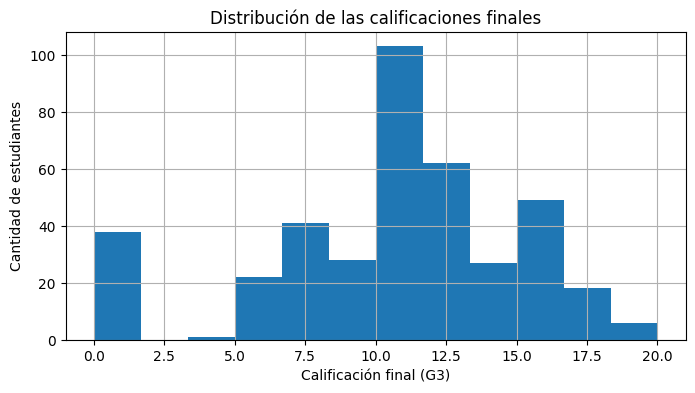

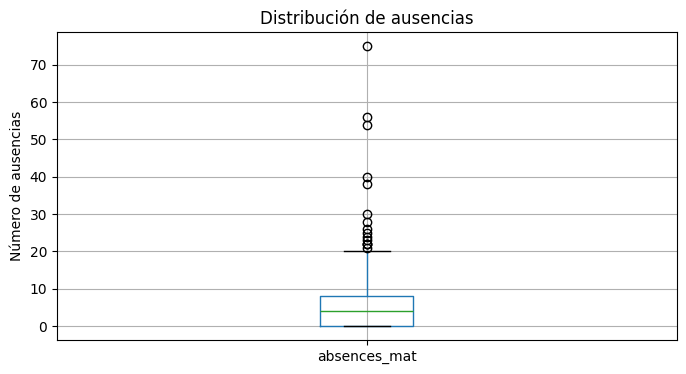

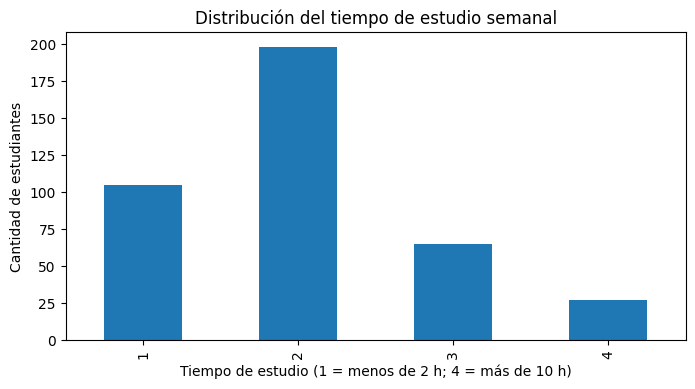

In [7]:
# Gráfica 1: distribución de calificaciones finales
plt.figure(figsize=(8, 4))
datos["G3_mat"].hist(bins=12)
plt.title("Distribución de las calificaciones finales")
plt.xlabel("Calificación final (G3)")
plt.ylabel("Cantidad de estudiantes")
plt.show()

# Gráfica 2: valores atípicos de ausencias
plt.figure(figsize=(8, 4))
datos.boxplot(column="absences_mat")
plt.title("Distribución de ausencias")
plt.ylabel("Número de ausencias")
plt.show()

# Gráfica 3: frecuencia del tiempo de estudio
plt.figure(figsize=(8, 4))
datos["studytime_mat"].value_counts().sort_index().plot(kind="bar")
plt.title("Distribución del tiempo de estudio semanal")
plt.xlabel("Tiempo de estudio (1 = menos de 2 h; 4 = más de 10 h)")
plt.ylabel("Cantidad de estudiantes")
plt.show()

### Hallazgos del análisis exploratorio – Matemáticas

A partir de la muestra completa de Matemáticas, preparé cinco hallazgos sobre el rendimiento general, el tiempo de estudio, las reprobaciones previas, las ausencias y el apoyo escolar adicional. Las cifras se calculan en la celda siguiente; al volver a ejecutar el notebook, conviene revisar que la interpretación siga correspondiendo a los resultados que aparecen.

Más adelante se incluyen cinco hallazgos comparativos que consideran también el archivo de Portugués.


In [8]:
# Hallazgo 1: rendimiento general y proporción de bajo rendimiento
promedio_g3 = datos["G3_mat"].mean()
mediana_g3 = datos["G3_mat"].median()
porcentaje_bajo = y.mean() * 100
print(
    f"1. Rendimiento general: la media de G3 es {promedio_g3:.2f}/20 y "
    f"la mediana es {mediana_g3:.2f}/20. El {porcentaje_bajo:.1f}% de los "
    "estudiantes presenta bajo rendimiento (G3 < 10). Esto permite dimensionar "
    "la proporción que podría requerir seguimiento."
)

# Hallazgo 2: tiempo de estudio
promedios_estudio = datos.groupby("studytime_mat")["G3_mat"].mean().sort_index()
conteos_estudio = datos["studytime_mat"].value_counts().sort_index()
if len(promedios_estudio) >= 2:
    nivel_mayor = int(promedios_estudio.idxmax())
    nivel_menor = int(promedios_estudio.idxmin())
    print(
        f"2. Tiempo de estudio: el promedio más alto de G3 aparece en la categoría "
        f"{nivel_mayor} ({promedios_estudio.max():.2f}; n={conteos_estudio[nivel_mayor]}), "
        f"y el más bajo en la categoría {nivel_menor} ({promedios_estudio.min():.2f}; "
        f"n={conteos_estudio[nivel_menor]}). La diferencia sugiere una asociación "
        "que merece seguimiento, pero no prueba que estudiar más cause una nota mayor."
    )

# Hallazgo 3: reprobaciones previas
sin_reprobaciones = datos.loc[datos["failures_mat"] == 0, "G3_mat"]
con_reprobaciones = datos.loc[datos["failures_mat"] > 0, "G3_mat"]
if len(sin_reprobaciones) and len(con_reprobaciones):
    print(
        f"3. Reprobaciones previas: el promedio de G3 es {sin_reprobaciones.mean():.2f} "
        f"sin reprobaciones previas (n={len(sin_reprobaciones)}) y "
        f"{con_reprobaciones.mean():.2f} con al menos una reprobación (n={len(con_reprobaciones)}). "
        "El antecedente de reprobación puede ser una señal útil para priorizar acompañamiento."
    )

# Hallazgo 4: ausencias y calificación final
correlacion_ausencias = datos["absences_mat"].corr(datos["G3_mat"])
print(
    f"4. Ausencias y calificación: la correlación de Pearson entre ausencias y G3 es "
    f"{correlacion_ausencias:.3f}. Este valor describe la intensidad y dirección de la "
    "asociación lineal en la muestra; por sí solo no permite concluir causalidad."
)

# Hallazgo 5: apoyo escolar extra
if "schoolsup_mat" in datos.columns:
    tabla_apoyo = datos.assign(bajo_rendimiento=y).groupby("schoolsup_mat").agg(
        estudiantes=("G3_mat", "size"),
        promedio_G3=("G3_mat", "mean"),
        porcentaje_bajo=("bajo_rendimiento", lambda s: s.mean() * 100)
    )
    print("5. Apoyo escolar adicional: promedio final y porcentaje de bajo rendimiento por grupo (yes/no).")
    display(tabla_apoyo.round(2))
    print("La tabla permite comparar descriptivamente los grupos; el apoyo no debe interpretarse como causa del resultado, porque puede ofrecerse precisamente a estudiantes que ya presentan dificultades.")

1. Rendimiento general: la media de G3 es 10.42/20 y la mediana es 11.00/20. El 32.9% de los estudiantes presenta bajo rendimiento (G3 < 10). Esto permite dimensionar la proporción que podría requerir seguimiento.
2. Tiempo de estudio: el promedio más alto de G3 aparece en la categoría 3 (11.40; n=65), y el más bajo en la categoría 1 (10.05; n=105). La diferencia sugiere una asociación que merece seguimiento, pero no prueba que estudiar más cause una nota mayor.
3. Reprobaciones previas: el promedio de G3 es 11.25 sin reprobaciones previas (n=312) y 7.27 con al menos una reprobación (n=83). El antecedente de reprobación puede ser una señal útil para priorizar acompañamiento.
4. Ausencias y calificación: la correlación de Pearson entre ausencias y G3 es 0.034. Este valor describe la intensidad y dirección de la asociación lineal en la muestra; por sí solo no permite concluir causalidad.
5. Apoyo escolar adicional: promedio final y porcentaje de bajo rendimiento por grupo (yes/no).


,estudiantes,promedio_G3,porcentaje_bajo
schoolsup_mat,,,
no,344,10.56,31.1
yes,51,9.43,45.1


La tabla permite comparar descriptivamente los grupos; el apoyo no debe interpretarse como causa del resultado, porque puede ofrecerse precisamente a estudiantes que ya presentan dificultades.


## Análisis exploratorio comparativo: Matemáticas y Portugués

Después de revisar cada archivo por separado, preparé una comparación general de las dos asignaturas. La comparación se hace con promedios y porcentajes de cada conjunto; no significa que cada fila de Matemáticas se haya emparejado con la misma persona en Portugués.


COMPARACIÓN GENERAL DE LAS DOS BASES


,Asignatura,Registros,Promedio G3,Porcentaje bajo rendimiento,Promedio ausencias,Promedio G1,Promedio G2
0,Matemáticas,395,10.42,32.91,5.71,10.91,10.71
1,Portugués,649,11.91,15.41,3.66,11.40,11.57


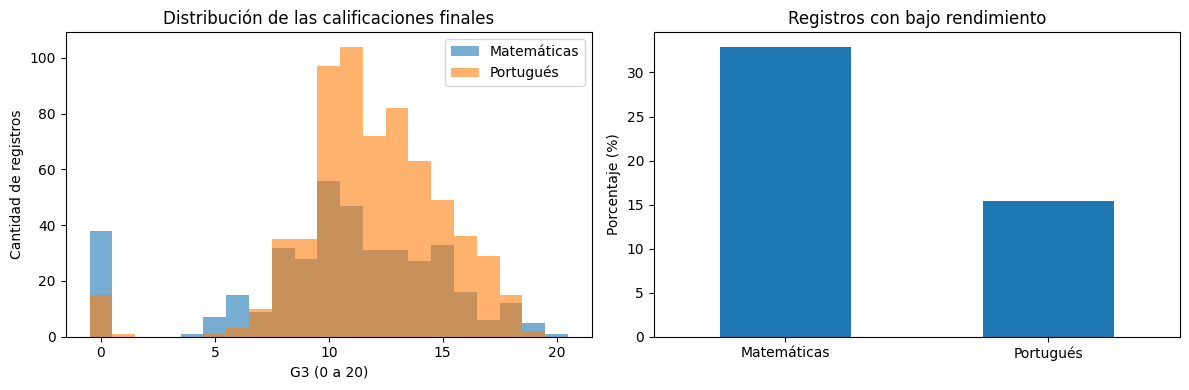

HALLAZGOS COMPARATIVOS
1. Tamaño: Matemáticas tiene 395 registros y Portugués 649; por eso los porcentajes son más comparables que los conteos absolutos.
2. Nota final: el promedio de G3 fue 10.42 en Matemáticas y 11.91 en Portugués.
3. Bajo rendimiento: el porcentaje con G3 < 10 fue 32.91% en Matemáticas y 15.41% en Portugués.
4. Ausencias: el promedio fue 5.71 en Matemáticas y 3.66 en Portugués.
5. Reprobaciones anteriores: la diferencia entre el promedio de quienes no reportan reprobaciones y quienes sí reportan es 3.99 puntos en Matemáticas y 3.92 en Portugués. Es una asociación descriptiva, no una relación causal.


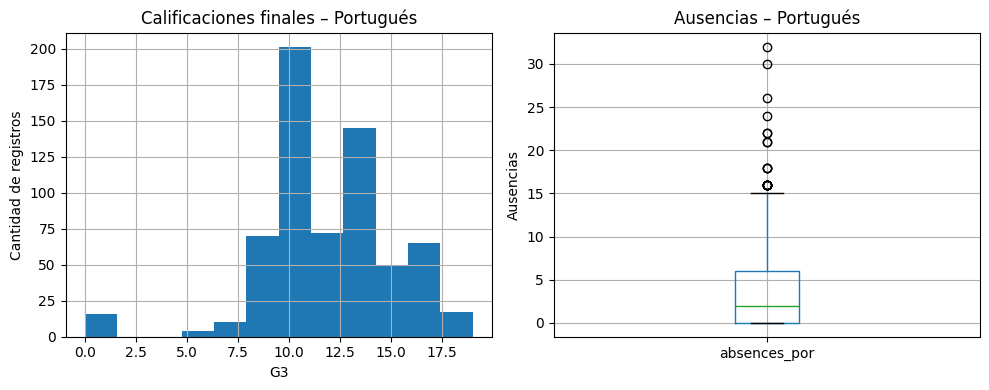

In [9]:
UMBRAL_BAJO_RENDIMIENTO = 10
y_por = (datos_por["G3_por"] < UMBRAL_BAJO_RENDIMIENTO).astype(int).rename("bajo_rendimiento_por")

comparacion_asignaturas = pd.DataFrame([
    {
        "Asignatura": "Matemáticas",
        "Registros": len(datos),
        "Promedio G3": datos["G3_mat"].mean(),
        "Porcentaje bajo rendimiento": y.mean() * 100,
        "Promedio ausencias": datos["absences_mat"].mean(),
        "Promedio G1": datos["G1_mat"].mean(),
        "Promedio G2": datos["G2_mat"].mean()
    },
    {
        "Asignatura": "Portugués",
        "Registros": len(datos_por),
        "Promedio G3": datos_por["G3_por"].mean(),
        "Porcentaje bajo rendimiento": y_por.mean() * 100,
        "Promedio ausencias": datos_por["absences_por"].mean(),
        "Promedio G1": datos_por["G1_por"].mean(),
        "Promedio G2": datos_por["G2_por"].mean()
    }
]).round(2)

print("COMPARACIÓN GENERAL DE LAS DOS BASES")
display(comparacion_asignaturas)

# Gráficos comparativos con la misma escala para facilitar la lectura.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(datos["G3_mat"], bins=np.arange(-0.5, 21.5, 1), alpha=0.6, label="Matemáticas")
axes[0].hist(datos_por["G3_por"], bins=np.arange(-0.5, 21.5, 1), alpha=0.6, label="Portugués")
axes[0].set_title("Distribución de las calificaciones finales")
axes[0].set_xlabel("G3 (0 a 20)")
axes[0].set_ylabel("Cantidad de registros")
axes[0].legend()

comparacion_asignaturas.set_index("Asignatura")["Porcentaje bajo rendimiento"].plot(
    kind="bar", ax=axes[1]
)
axes[1].set_title("Registros con bajo rendimiento")
axes[1].set_ylabel("Porcentaje (%)")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

print("HALLAZGOS COMPARATIVOS")
mat_row = comparacion_asignaturas.set_index("Asignatura").loc["Matemáticas"]
por_row = comparacion_asignaturas.set_index("Asignatura").loc["Portugués"]
print(f"1. Tamaño: Matemáticas tiene {int(mat_row['Registros'])} registros y Portugués {int(por_row['Registros'])}; por eso los porcentajes son más comparables que los conteos absolutos.")
print(f"2. Nota final: el promedio de G3 fue {mat_row['Promedio G3']:.2f} en Matemáticas y {por_row['Promedio G3']:.2f} en Portugués.")
print(f"3. Bajo rendimiento: el porcentaje con G3 < 10 fue {mat_row['Porcentaje bajo rendimiento']:.2f}% en Matemáticas y {por_row['Porcentaje bajo rendimiento']:.2f}% en Portugués.")
print(f"4. Ausencias: el promedio fue {mat_row['Promedio ausencias']:.2f} en Matemáticas y {por_row['Promedio ausencias']:.2f} en Portugués.")
mat_fail = datos.loc[datos["failures_mat"] == 0, "G3_mat"].mean() - datos.loc[datos["failures_mat"] > 0, "G3_mat"].mean()
por_fail = datos_por.loc[datos_por["failures_por"] == 0, "G3_por"].mean() - datos_por.loc[datos_por["failures_por"] > 0, "G3_por"].mean()
print(f"5. Reprobaciones anteriores: la diferencia entre el promedio de quienes no reportan reprobaciones y quienes sí reportan es {mat_fail:.2f} puntos en Matemáticas y {por_fail:.2f} en Portugués. Es una asociación descriptiva, no una relación causal.")

# Gráficas adicionales para observar la distribución del segundo conjunto.
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
datos_por["G3_por"].hist(bins=12, ax=axes[0])
axes[0].set_title("Calificaciones finales – Portugués")
axes[0].set_xlabel("G3")
axes[0].set_ylabel("Cantidad de registros")
datos_por.boxplot(column="absences_por", ax=axes[1])
axes[1].set_title("Ausencias – Portugués")
axes[1].set_ylabel("Ausencias")
plt.tight_layout()
plt.show()


## 3. Ingeniería de características y pipeline

Para que los datos fueran más útiles en las siguientes etapas, construí tres variables derivadas:

1. `grade_progress_mat`: diferencia entre la segunda y la primera evaluación (`G2 - G1`). Solo sirve como predictor cuando ya se conoce G2.
2. `has_failures_mat`: indica si el estudiante reportó al menos una reprobación anterior.
3. `absence_level_mat`: agrupa las ausencias en cuatro niveles para facilitar su interpretación.

La función `preparar_features()` reúne estas transformaciones, convierte las variables categóricas en columnas numéricas y escala las ausencias con Min-Max. Las marcas de valores atípicos se mantienen en la base de calidad, pero no pasan a los predictores. La nota final `G3_mat` se conserva para construir la variable objetivo y se retira de `X` antes de entrenar el modelo.


In [10]:
def preparar_features(data):
    """Deriva variables, codifica categorías y escala ausencias de forma reproducible."""
    data = data.copy()

    # 1. Progreso académico entre la primera y segunda evaluación
    data["grade_progress_mat"] = data["G2_mat"] - data["G1_mat"]

    # 2. Indicador de al menos una reprobación previa
    data["has_failures_mat"] = (data["failures_mat"] > 0).astype(int)

    # 3. Clasificación del nivel de ausencias
    data["absence_level_mat"] = pd.cut(
        data["absences_mat"],
        bins=[-1, 0, 5, 15, float("inf")],
        labels=["Sin ausencias", "Bajas", "Medias", "Altas"]
    )

    # Evitar que los indicadores de revisión de calidad entren al modelo
    data = data.drop(
        columns=["marca_atipico_ausencias", "marca_atipico_G3"],
        errors="ignore"
    )

    # Codificar todas las variables categóricas
    columnas_categoricas = data.select_dtypes(
        include=["object", "category"]
    ).columns.tolist()
    if columnas_categoricas:
        data = pd.get_dummies(
            data,
            columns=columnas_categoricas,
            dtype=int
        )

    # Escalado Min-Max de ausencias
    minimo = data["absences_mat"].min()
    maximo = data["absences_mat"].max()
    if maximo != minimo:
        data["absences_scaled"] = (
            (data["absences_mat"] - minimo) / (maximo - minimo)
        )
    else:
        data["absences_scaled"] = 0.0

    return data

# Ejecutar el pipeline
UMBRAL_BAJO_RENDIMIENTO = 10
df_features = preparar_features(datos)
print("Dimensiones de la base transformada:", df_features.shape)
display(df_features.head())

# Verificar que no queden columnas object/category sin codificar
columnas_categoricas_pendientes = df_features.select_dtypes(
    include=["object", "category"]
).columns.tolist()
print("Columnas categóricas pendientes:", columnas_categoricas_pendientes)

# Comprobar reproducibilidad
# Dos ejecuciones sobre la misma entrada deben producir exactamente la misma salida.
df_v1 = preparar_features(datos)
df_v2 = preparar_features(datos)
print("¿El pipeline es reproducible?", df_v1.equals(df_v2))

Dimensiones de la base transformada: (395, 66)


,age_mat,Medu_mat,Fedu_mat,traveltime_mat,studytime_mat,failures_mat,famrel_mat,freetime_mat,goout_mat,Dalc_mat,...,higher_mat_yes,internet_mat_no,internet_mat_yes,romantic_mat_no,romantic_mat_yes,absence_level_mat_Sin ausencias,absence_level_mat_Bajas,absence_level_mat_Medias,absence_level_mat_Altas,absences_scaled
0,18,4,4,2,2,0,4,3,4,1,...,1,1,0,1,0,0,0,1,0,0.080000
1,17,1,1,1,2,0,5,3,3,1,...,1,0,1,1,0,0,1,0,0,0.053333
2,15,1,1,1,2,3,4,3,2,2,...,1,0,1,1,0,0,0,1,0,0.133333
3,15,4,2,1,3,0,3,2,2,1,...,1,0,1,0,1,0,1,0,0,0.026667
4,16,3,3,1,2,0,4,3,2,1,...,1,1,0,1,0,0,1,0,0,0.053333


Columnas categóricas pendientes: []
¿El pipeline es reproducible? True


### Preparación de la variable objetivo y los predictores

Definí `y = 1` cuando `G3_mat < 10` y `y = 0` cuando `G3_mat >= 10`. La nota final no se incluye en `X`, porque es justamente el resultado que se busca identificar.

Hay una consideración importante sobre el momento de uso: `grade_progress_mat` se calcula con G1 y G2. Por eso, el modelo representa una alerta que podría generarse después de conocer la segunda evaluación y antes de obtener G3. Si se necesitara una alerta más temprana, habría que retirar G1, G2 y `grade_progress_mat` de los predictores.

La columna `absences_scaled` se conserva en `df_features` para mostrar el escalado solicitado en la Unidad 4, pero se excluye del árbol de decisión. Los árboles no necesitan que sus variables estén escaladas y así tampoco se incorpora al modelo una transformación calculada antes de separar entrenamiento y prueba.


In [11]:
y = (datos["G3_mat"] < UMBRAL_BAJO_RENDIMIENTO).astype(int).rename("bajo_rendimiento")
X = df_features.drop(columns=["G3_mat", "absences_scaled"], errors="ignore")

print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)
print("Distribución del objetivo (0 = G3 >= 10; 1 = G3 < 10):")
display(y.value_counts().sort_index().rename(index={0: "Aprobación", 1: "Bajo rendimiento"}))

# Comprobaciones explícitas de fuga directa y tipos de predictores
print("¿G3_mat está dentro de X?", "G3_mat" in X.columns)
print("¿bajo_rendimiento está dentro de X?", "bajo_rendimiento" in X.columns)
print("¿absences_scaled está dentro de X?", "absences_scaled" in X.columns)
print("Columnas no numéricas en X:", X.select_dtypes(exclude=["number", "bool"]).columns.tolist())


Dimensiones de X: (395, 64)
Dimensiones de y: (395,)
Distribución del objetivo (0 = G3 >= 10; 1 = G3 < 10):


,count
bajo_rendimiento,
Aprobación,265
Bajo rendimiento,130


¿G3_mat está dentro de X? False
¿bajo_rendimiento está dentro de X? False
¿absences_scaled está dentro de X? False
Columnas no numéricas en X: []


### Ingeniería de características para el archivo de Portugués

Apliqué el mismo criterio de preparación al segundo archivo, pero manteniendo sus columnas con el sufijo `_por`. Así cada asignatura conserva su propio pipeline y luego se pueden comparar los resultados sin mezclar registros.


In [12]:
def preparar_features_por(data):
    data = data.copy()

    # Variables derivadas a partir de información disponible antes de G3.
    data["grade_progress_por"] = data["G2_por"] - data["G1_por"]
    data["has_failures_por"] = (data["failures_por"] > 0).astype(int)
    data["absence_level_por"] = pd.cut(
        data["absences_por"],
        bins=[-1, 0, 5, 15, float("inf")],
        labels=["Sin ausencias", "Bajas", "Medias", "Altas"]
    )

    data = data.drop(
        columns=["marca_atipico_ausencias_por", "marca_atipico_G3_por"],
        errors="ignore"
    )
    columnas_categoricas = data.select_dtypes(
        include=["object", "category"]
    ).columns.tolist()
    if columnas_categoricas:
        data = pd.get_dummies(data, columns=columnas_categoricas, dtype=int)

    minimo = data["absences_por"].min()
    maximo = data["absences_por"].max()
    data["absences_scaled_por"] = (
        (data["absences_por"] - minimo) / (maximo - minimo)
        if maximo != minimo else 0.0
    )
    return data


df_features_por = preparar_features_por(datos_por)
X_por = df_features_por.drop(
    columns=["G3_por", "absences_scaled_por"], errors="ignore"
)
y_por = (datos_por["G3_por"] < UMBRAL_BAJO_RENDIMIENTO).astype(int).rename("bajo_rendimiento_por")

print("Dimensiones de la base transformada de Portugués:", df_features_por.shape)
print("Dimensiones de X_por:", X_por.shape)
print("Distribución del objetivo:")
display(y_por.value_counts().rename(index={0: "Rendimiento no bajo", 1: "Bajo rendimiento"}))
print("Columnas categóricas pendientes:", df_features_por.select_dtypes(include=["object", "category"]).columns.tolist())
print("¿El pipeline de Portugués es reproducible?", preparar_features_por(datos_por).equals(preparar_features_por(datos_por)))
print("¿G3_por está dentro de X_por?", "G3_por" in X_por.columns)


Dimensiones de la base transformada de Portugués: (649, 66)
Dimensiones de X_por: (649, 64)
Distribución del objetivo:


,count
bajo_rendimiento_por,
Rendimiento no bajo,549
Bajo rendimiento,100


Columnas categóricas pendientes: []
¿El pipeline de Portugués es reproducible? True
¿G3_por está dentro de X_por? False


## 4. Segmentación y asociación –  (Matemáticas)

### Segmentación inicial con K-means

Para esta parte seguí la indicación de trabajar con dos variables numéricas relacionadas con la pregunta del proyecto. Elegí:

- `absences_mat`, que representa la asistencia.
- `G2_mat`, que muestra el rendimiento conocido al terminar la segunda evaluación.

Estandaricé ambas variables antes de aplicar K-means. La calificación final `G3_mat` no se utiliza para formar los grupos; la consulto después para describir cómo se comportó cada segmento. Para orientar la selección de k, comparé la curva del codo (de 1 a 6 grupos) y el índice Silhouette.

Después de esta primera ejecución, la misma metodología se aplica a la base de Portugués en el bloque comparativo que sigue.


Método del codo: buscar dónde la inercia deja de disminuir fuertemente.


,k,inercia
0,1,790.000
1,2,538.379
2,3,350.652
3,4,253.925
4,5,187.542
5,6,155.048


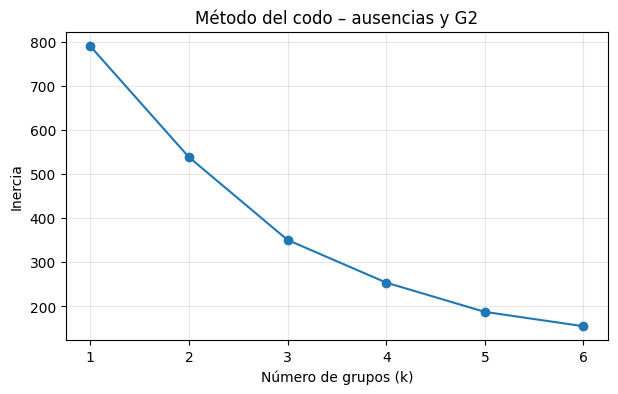

Comparación complementaria con Silhouette:


,k,silhouette
0,4,0.417
1,3,0.400
2,5,0.399
3,6,0.373
4,2,0.347


Número de grupos elegido inicialmente por Silhouette: 4
Revisa también la curva del codo; si sugiere otro k, justifica y cambia k_elegido.
Perfil descriptivo de los segmentos K-means:


,estudiantes,promedio_ausencias,promedio_G2,promedio_G3,promedio_tiempo_estudio,promedio_reprobaciones,porcentaje_bajo_rendimiento
cluster,,,,,,,
0,171,2.95,13.80,13.91,2.12,0.08,0.58
1,82,14.28,9.82,9.96,1.90,0.50,41.46
2,137,2.31,7.43,6.36,2.01,0.55,67.15
3,5,52.60,10.00,9.40,2.00,0.40,60.00


INTERPRETACIÓN AUTOMÁTICA DE CADA SEGMENTO:
- Cluster 0: n=171; G2 promedio=13.80; G3 promedio=13.91; ausencias promedio=2.95; reprobaciones previas promedio=0.08; bajo rendimiento=0.6%. Este grupo presenta una proporción relativamente baja de bajo rendimiento.
- Cluster 1: n=82; G2 promedio=9.82; G3 promedio=9.96; ausencias promedio=14.28; reprobaciones previas promedio=0.50; bajo rendimiento=41.5%. Este grupo presenta una proporción intermedia de bajo rendimiento.
- Cluster 2: n=137; G2 promedio=7.43; G3 promedio=6.36; ausencias promedio=2.31; reprobaciones previas promedio=0.55; bajo rendimiento=67.2%. Este grupo concentra una proporción alta de bajo rendimiento.
- Cluster 3: n=5; G2 promedio=10.00; G3 promedio=9.40; ausencias promedio=52.60; reprobaciones previas promedio=0.40; bajo rendimiento=60.0%. Este grupo concentra una proporción alta de bajo rendimiento.

RESUMEN DE LOS EXTREMOS:
- Mayor proporción de bajo rendimiento: cluster 2 (67.2%).
- Menor proporción de bajo rendimien

In [13]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# La guía de Unidad 5 pide elegir dos variables numéricas relevantes.
columnas_segmentacion = ["absences_mat", "G2_mat"]
X_segmentacion = datos[columnas_segmentacion].copy()

if X_segmentacion.isnull().any().any():
    raise ValueError("Hay valores nulos en las variables de segmentación. Revísalos antes de continuar.")

escalador_segmentacion = StandardScaler()
X_segmentacion_escalado = escalador_segmentacion.fit_transform(X_segmentacion)

# 1. Método del codo: calcular inercia para k entre 1 y 6.
resultados_codo = []
for k in range(1, 7):
    modelo_k = KMeans(n_clusters=k, random_state=42, n_init=10)
    modelo_k.fit(X_segmentacion_escalado)
    resultados_codo.append({"k": k, "inercia": modelo_k.inertia_})

tabla_codo = pd.DataFrame(resultados_codo)
print("Método del codo: buscar dónde la inercia deja de disminuir fuertemente.")
display(tabla_codo.round(3))

plt.figure(figsize=(7, 4))
plt.plot(tabla_codo["k"], tabla_codo["inercia"], marker="o")
plt.xlabel("Número de grupos (k)")
plt.ylabel("Inercia")
plt.title("Método del codo – ausencias y G2")
plt.xticks(range(1, 7))
plt.grid(alpha=0.3)
plt.show()

# 2. Silhouette como criterio complementario para k entre 2 y 6.
resultados_silhouette = []
for k in range(2, 7):
    modelo_k = KMeans(n_clusters=k, random_state=42, n_init=10)
    etiquetas_k = modelo_k.fit_predict(X_segmentacion_escalado)
    resultados_silhouette.append({
        "k": k,
        "silhouette": silhouette_score(X_segmentacion_escalado, etiquetas_k)
    })

comparacion_k = pd.DataFrame(resultados_silhouette).sort_values(
    "silhouette", ascending=False
).reset_index(drop=True)
print("Comparación complementaria con Silhouette:")
display(comparacion_k.round(3))

# Selección reproducible inicial: mayor Silhouette; contrastar visualmente con el codo.
k_elegido = int(comparacion_k.loc[0, "k"])
print("Número de grupos elegido inicialmente por Silhouette:", k_elegido)
print("Revisa también la curva del codo; si sugiere otro k, justifica y cambia k_elegido.")

modelo_segmentacion = KMeans(
    n_clusters=k_elegido, random_state=42, n_init=10
)
clusters = modelo_segmentacion.fit_predict(X_segmentacion_escalado)

resultado_segmentacion = datos.copy()
resultado_segmentacion["cluster"] = clusters
resultado_segmentacion["bajo_rendimiento"] = y.values

# G3 se usa solo para describir los grupos después de haberlos formado.
resumen_clusters = resultado_segmentacion.groupby("cluster").agg(
    estudiantes=("G3_mat", "size"),
    promedio_ausencias=("absences_mat", "mean"),
    promedio_G2=("G2_mat", "mean"),
    promedio_G3=("G3_mat", "mean"),
    promedio_tiempo_estudio=("studytime_mat", "mean"),
    promedio_reprobaciones=("failures_mat", "mean"),
    porcentaje_bajo_rendimiento=("bajo_rendimiento", lambda s: s.mean() * 100)
).round(2)

print("Perfil descriptivo de los segmentos K-means:")
display(resumen_clusters)

# Interpretaciones generadas para cada cluster con los resultados de esta ejecución.
cluster_mayor_riesgo = resumen_clusters["porcentaje_bajo_rendimiento"].idxmax()
cluster_menor_riesgo = resumen_clusters["porcentaje_bajo_rendimiento"].idxmin()
cluster_mas_ausencias = resumen_clusters["promedio_ausencias"].idxmax()
cluster_g3_mas_alto = resumen_clusters["promedio_G3"].idxmax()

print("INTERPRETACIÓN AUTOMÁTICA DE CADA SEGMENTO:")
for cluster_id, fila in resumen_clusters.iterrows():
    porcentaje = fila["porcentaje_bajo_rendimiento"]
    if porcentaje >= 50:
        lectura_riesgo = "concentra una proporción alta de bajo rendimiento"
    elif porcentaje >= 25:
        lectura_riesgo = "presenta una proporción intermedia de bajo rendimiento"
    else:
        lectura_riesgo = "presenta una proporción relativamente baja de bajo rendimiento"
    print(
        f"- Cluster {cluster_id}: n={int(fila['estudiantes'])}; "
        f"G2 promedio={fila['promedio_G2']:.2f}; G3 promedio={fila['promedio_G3']:.2f}; "
        f"ausencias promedio={fila['promedio_ausencias']:.2f}; "
        f"reprobaciones previas promedio={fila['promedio_reprobaciones']:.2f}; "
        f"bajo rendimiento={porcentaje:.1f}%. Este grupo {lectura_riesgo}."
    )
print("\nRESUMEN DE LOS EXTREMOS:")
print(f"- Mayor proporción de bajo rendimiento: cluster {cluster_mayor_riesgo} ({resumen_clusters.loc[cluster_mayor_riesgo, 'porcentaje_bajo_rendimiento']:.1f}%).")
print(f"- Menor proporción de bajo rendimiento: cluster {cluster_menor_riesgo} ({resumen_clusters.loc[cluster_menor_riesgo, 'porcentaje_bajo_rendimiento']:.1f}%).")
print(f"- Mayor promedio de ausencias: cluster {cluster_mas_ausencias} ({resumen_clusters.loc[cluster_mas_ausencias, 'promedio_ausencias']:.2f}).")
print(f"- Mayor promedio de calificación final G3: cluster {cluster_g3_mas_alto} ({resumen_clusters.loc[cluster_g3_mas_alto, 'promedio_G3']:.2f}/20).")
print("Los números de cluster son etiquetas técnicas, no un orden de rendimiento.")


### Interpretación descriptiva de los segmentos

La tabla de la celda anterior resume el tamaño y las características de cada grupo. También muestra qué segmento tiene mayor o menor proporción de bajo rendimiento, más ausencias y mayor promedio de G3.

Al explicar los resultados, es importante describir los grupos con sus tamaños y promedios, sin asumir que los números de cluster representan un orden. En particular, un grupo muy pequeño —como el que tiene solo cinco estudiantes en esta ejecución— debe interpretarse con cuidado y no como un perfil general de toda la población.

G3 se utiliza únicamente para revisar cómo quedó cada grupo después de ejecutar K-means; no participa en la formación de los clusters. La cantidad de grupos se eligió con Silhouette y se contrastó con la curva del codo. Por eso, la selección se presenta como una decisión exploratoria y no como una respuesta única.


### Comparación con clustering jerárquico

Después de K-means, apliqué clustering jerárquico usando la misma matriz estandarizada de ausencias y G2. Mantuve la misma cantidad de grupos (`k_elegido`) y utilicé el método `ward`. La tabla cruzada permite ver en qué medida las dos técnicas asignaron a los estudiantes a grupos parecidos. Los números de las etiquetas son códigos, no categorías con un orden propio.


In [14]:
from sklearn.cluster import AgglomerativeClustering

modelo_jerarquico = AgglomerativeClustering(
    n_clusters=k_elegido,
    linkage="ward"
)

etiquetas_jerarquicas = modelo_jerarquico.fit_predict(X_segmentacion_escalado)
resultado_segmentacion["cluster_jerarquico"] = etiquetas_jerarquicas

tabla_cruzada_clusters = pd.crosstab(
    resultado_segmentacion["cluster"],
    resultado_segmentacion["cluster_jerarquico"],
    rownames=["K-means"],
    colnames=["Jerárquico"]
)

print("Comparación de asignaciones: K-means frente a clustering jerárquico")
display(tabla_cruzada_clusters)

print("Cantidad de estudiantes por grupo jerárquico:")
display(resultado_segmentacion["cluster_jerarquico"].value_counts().sort_index())

print("La tabla cruzada compara coincidencias de asignación; los números de cluster de cada técnica no tienen un significado ordinal.")


Comparación de asignaciones: K-means frente a clustering jerárquico


Jerárquico,0,1,2,3
K-means,,,,
0,46,125,0,0
1,0,20,62,0
2,132,0,5,0
3,0,0,0,5


Cantidad de estudiantes por grupo jerárquico:


,count
cluster_jerarquico,
0,178
1,145
2,67
3,5


La tabla cruzada compara coincidencias de asignación; los números de cluster de cada técnica no tienen un significado ordinal.


### Segmentación con DBSCAN

También probé DBSCAN sobre las mismas dos variables estandarizadas. A diferencia de K-means, este método busca zonas de mayor densidad y puede dejar algunos registros como ruido, identificados con la etiqueta `-1`.

Probé distintos valores de `eps`, manteniendo `min_samples=5`, y revisé cuántos grupos se formaban y qué porcentaje de registros quedaba como ruido. Si los resultados no forman grupos que se puedan interpretar, es mejor reportar esa limitación que forzar una conclusión.


In [15]:
from sklearn.cluster import DBSCAN

# Valores candidatos de eps para la matriz estandarizada de dos variables.
eps_candidatos = [0.3, 0.5, 0.7, 0.9, 1.1, 1.3, 1.5, 1.8, 2.0, 2.5]
min_samples_dbscan = 5
resultados_dbscan = []
modelos_dbscan = {}

for eps in eps_candidatos:
    modelo_db = DBSCAN(eps=eps, min_samples=min_samples_dbscan)
    etiquetas = modelo_db.fit_predict(X_segmentacion_escalado)
    modelos_dbscan[eps] = etiquetas

    grupos = set(etiquetas) - {-1}
    cantidad_grupos = len(grupos)
    cantidad_ruido = int((etiquetas == -1).sum())
    porcentaje_ruido = cantidad_ruido / len(etiquetas) * 100

    mascara_no_ruido = etiquetas != -1
    etiquetas_sin_ruido = etiquetas[mascara_no_ruido]
    silhouette_db = np.nan
    if (cantidad_grupos >= 2 and
        2 <= len(set(etiquetas_sin_ruido)) < len(etiquetas_sin_ruido)):
        silhouette_db = silhouette_score(
            X_segmentacion_escalado[mascara_no_ruido],
            etiquetas_sin_ruido
        )

    resultados_dbscan.append({
        "eps": eps,
        "cantidad_grupos": cantidad_grupos,
        "registros_ruido": cantidad_ruido,
        "porcentaje_ruido": porcentaje_ruido,
        "silhouette_sin_ruido": silhouette_db
    })

tabla_dbscan = pd.DataFrame(resultados_dbscan)
print("Comparación de parámetros DBSCAN (-1 representa ruido):")
display(tabla_dbscan.round(3))

# Criterio exploratorio: al menos dos grupos, Silhouette calculable y hasta 50% de ruido.
# El 50% es una referencia práctica de esta exploración, no una regla universal.
soluciones_validas = tabla_dbscan[
    (tabla_dbscan["cantidad_grupos"] >= 2) &
    (tabla_dbscan["porcentaje_ruido"] <= 50) &
    (tabla_dbscan["silhouette_sin_ruido"].notna())
]

if not soluciones_validas.empty:
    fila_elegida = soluciones_validas.sort_values(
        "silhouette_sin_ruido", ascending=False
    ).iloc[0]
    eps_elegido = float(fila_elegida["eps"])
    etiquetas_dbscan = modelos_dbscan[eps_elegido]
    resultado_segmentacion["cluster_dbscan"] = etiquetas_dbscan

    print(f"Valor eps seleccionado de forma preliminar: {eps_elegido}")
    print("Grupos DBSCAN (sin contar -1):", len(set(etiquetas_dbscan) - {-1}))
    print("Distribución de etiquetas DBSCAN (-1 = ruido):")
    display(pd.Series(etiquetas_dbscan, name="cluster_dbscan").value_counts().sort_index())
else:
    eps_elegido = None
    print(
        "Ningún eps probado produjo una solución con al menos dos grupos, "
        "Silhouette calculable y como máximo 50% de ruido. DBSCAN no se considera "
        "una segmentación interpretable con esta configuración; se documenta como limitación."
    )


Comparación de parámetros DBSCAN (-1 representa ruido):


,eps,cantidad_grupos,registros_ruido,porcentaje_ruido,silhouette_sin_ruido
0,0.3,4,27,6.835,0.165
1,0.5,2,14,3.544,0.548
2,0.7,2,9,2.278,0.541
3,0.9,2,7,1.772,0.537
4,1.1,1,4,1.013,NaN
5,1.3,1,4,1.013,NaN
6,1.5,1,3,0.759,NaN
7,1.8,1,2,0.506,NaN
8,2.0,1,2,0.506,NaN
9,2.5,1,0,0.000,NaN


Valor eps seleccionado de forma preliminar: 0.5
Grupos DBSCAN (sin contar -1): 2
Distribución de etiquetas DBSCAN (-1 = ruido):


,count
cluster_dbscan,
-1,14
0,368
1,13


### Reglas de asociación (Apriori): ¿aplica a este dataset?

No apliqué Apriori porque la base tiene una fila por estudiante y reúne características académicas, familiares y de comportamiento. No contiene canastas o transacciones en las que se registren varios ítems juntos, que es la estructura que necesita este método. Por eso, para este proyecto no sería adecuado inventar transacciones solo para aplicar el algoritmo.

### Comparación breve de técnicas (reto opcional de Unidad 5)

- **K-means:** fue útil para construir perfiles a partir de ausencias y G2, definiendo previamente la cantidad de grupos.
- **Clustering jerárquico:** permitió comparar otra forma de agrupar los mismos registros y revisar las coincidencias con K-means mediante una tabla cruzada.
- **DBSCAN:** sirvió para explorar agrupaciones por densidad y detectar observaciones que quedan aisladas. Su resultado depende de `eps`; si deja un solo grupo o demasiados registros como ruido, pierde utilidad para describir perfiles.

En este conjunto, K-means ofrece una lectura directa de los perfiles y el método jerárquico sirve como contraste. DBSCAN aporta otra perspectiva al señalar puntos aislados. La elección no significa que una técnica sea siempre mejor que las demás; depende de lo que muestran los resultados y de la pregunta que se quiere responder.


### Resultados de la comparación de técnicas

En la primera corrida, correspondiente a Matemáticas (395 registros), obtuve los siguientes resultados:

- **K-means:** el mayor Silhouette entre los valores evaluados fue **0,417 para k=4**. La inercia baja de 790,000 con un grupo a 253,925 con cuatro grupos, y después continúa disminuyendo con cambios menores. Por eso trabajé con cuatro grupos como una opción inicial respaldada por ambos criterios, aunque no es la única solución posible.
- **Perfiles de K-means:** el cluster 0 reúne 171 estudiantes (G3 promedio de 13,91 y 0,58 % de bajo rendimiento); el cluster 1, 82 estudiantes (G3 de 9,96 y 41,46 % de bajo rendimiento); el cluster 2, 137 estudiantes (G3 de 6,36 y 67,15 % de bajo rendimiento); y el cluster 3, solo 5 estudiantes (52,60 ausencias promedio y 60 % de bajo rendimiento). Este último grupo es muy pequeño y se debe leer con cautela: refleja un perfil extremo de ausencias en esta muestra.
- **Clustering jerárquico:** la tabla cruzada muestra coincidencias parciales con K-means, pero no una asignación idéntica. Los números de cluster son etiquetas arbitrarias; lo importante es comparar tamaños y perfiles.
- **DBSCAN:** con `eps=0.5` y `min_samples=5` se formaron 2 grupos y 14 registros quedaron como ruido (3,5 %). El Silhouette de 0,548 se calculó solo con los registros que no fueron marcados como ruido. Por eso no debe compararse directamente con el Silhouette de K-means, que se calculó con todos los registros.

Estos resultados corresponden únicamente a Matemáticas. La misma revisión se repite en la sección siguiente para Portugués. En esta muestra, K-means fue práctico para resumir perfiles, el método jerárquico permitió contrastarlos y DBSCAN señaló un pequeño conjunto de observaciones aisladas. Los resultados son exploratorios: los grupos pequeños y la separación entre ellos deben tenerse presentes al interpretarlos. Apriori no aplica porque la base no tiene estructura de transacciones.



### Aplicación de segmentación al archivo de Portugués

Para no dejar el segundo archivo solo en una comparación descriptiva, repetí las técnicas de la Unidad 5 sobre `student-por.csv`. Usé las mismas dos variables (`absences_por` y `G2_por`), la misma estandarización y los mismos criterios de evaluación. Los clusters de Portugués se interpretan dentro de esa base; no se comparan fila a fila con los clusters de Matemáticas.


In [16]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score

columnas_segmentacion_por = ["absences_por", "G2_por"]
X_segmentacion_por = datos_por[columnas_segmentacion_por].copy()
if X_segmentacion_por.isnull().any().any():
    raise ValueError("Hay valores nulos en las variables de segmentación de Portugués.")

escalador_por = StandardScaler()
X_segmentacion_por_escalado = escalador_por.fit_transform(X_segmentacion_por)

# Método del codo y Silhouette.
resultados_codo_por = []
for k in range(1, 7):
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_segmentacion_por_escalado)
    resultados_codo_por.append({"k": k, "inercia": km.inertia_})
tabla_codo_por = pd.DataFrame(resultados_codo_por)
display(tabla_codo_por.round(3))

resultados_silhouette_por = []
for k in range(2, 7):
    etiquetas = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X_segmentacion_por_escalado)
    resultados_silhouette_por.append({"k": k, "silhouette": silhouette_score(X_segmentacion_por_escalado, etiquetas)})
comparacion_k_por = pd.DataFrame(resultados_silhouette_por).sort_values("silhouette", ascending=False).reset_index(drop=True)
print("Comparación de Silhouette – Portugués:")
display(comparacion_k_por.round(3))
k_elegido_por = int(comparacion_k_por.iloc[0]["k"])
print("Cantidad de grupos seleccionada preliminarmente:", k_elegido_por)

modelo_kmeans_por = KMeans(n_clusters=k_elegido_por, random_state=42, n_init=10)
clusters_por = modelo_kmeans_por.fit_predict(X_segmentacion_por_escalado)
resultado_segmentacion_por = datos_por.copy()
resultado_segmentacion_por["cluster_por"] = clusters_por
resultado_segmentacion_por["bajo_rendimiento_por"] = y_por.values
resumen_clusters_por = resultado_segmentacion_por.groupby("cluster_por").agg(
    registros=("G3_por", "size"),
    promedio_ausencias=("absences_por", "mean"),
    promedio_G2=("G2_por", "mean"),
    promedio_G3=("G3_por", "mean"),
    porcentaje_bajo_rendimiento=("bajo_rendimiento_por", lambda s: s.mean() * 100)
).round(2)
print("Perfiles de K-means – Portugués:")
display(resumen_clusters_por)
print("Lectura de los grupos de Portugués:")
for cluster_id, fila in resumen_clusters_por.iterrows():
    if fila["porcentaje_bajo_rendimiento"] >= 50:
        lectura = "concentra una proporción alta de bajo rendimiento"
    elif fila["porcentaje_bajo_rendimiento"] >= 25:
        lectura = "presenta una proporción intermedia de bajo rendimiento"
    else:
        lectura = "presenta una proporción relativamente baja de bajo rendimiento"
    print(
        f"- Cluster {cluster_id}: {int(fila['registros'])} registros, "
        f"G3 promedio={fila['promedio_G3']:.2f}, "
        f"ausencias promedio={fila['promedio_ausencias']:.2f} y "
        f"bajo rendimiento={fila['porcentaje_bajo_rendimiento']:.1f}%; este grupo {lectura}."
    )

# Clustering jerárquico con el mismo número de grupos y la misma matriz.
modelo_jerarquico_por = AgglomerativeClustering(n_clusters=k_elegido_por, linkage="ward")
resultado_segmentacion_por["cluster_jerarquico_por"] = modelo_jerarquico_por.fit_predict(X_segmentacion_por_escalado)
print("Comparación K-means vs. jerárquico – Portugués:")
display(pd.crosstab(resultado_segmentacion_por["cluster_por"], resultado_segmentacion_por["cluster_jerarquico_por"]))

# DBSCAN: se comparan varios eps y se elige una solución no degenerada.
eps_candidatos_por = [0.3, 0.5, 0.7, 0.9, 1.1, 1.3, 1.5, 1.8, 2.0, 2.5]
resultados_dbscan_por = []
modelos_dbscan_por = {}
for eps in eps_candidatos_por:
    etiquetas = DBSCAN(eps=eps, min_samples=5).fit_predict(X_segmentacion_por_escalado)
    modelos_dbscan_por[eps] = etiquetas
    grupos = set(etiquetas) - {-1}
    n_grupos = len(grupos)
    n_ruido = int((etiquetas == -1).sum())
    mascara = etiquetas != -1
    sil = np.nan
    if n_grupos >= 2 and 2 <= len(set(etiquetas[mascara])) < mascara.sum():
        sil = silhouette_score(X_segmentacion_por_escalado[mascara], etiquetas[mascara])
    resultados_dbscan_por.append({
        "eps": eps,
        "grupos": n_grupos,
        "ruido": n_ruido,
        "porcentaje_ruido": n_ruido / len(etiquetas) * 100,
        "silhouette_sin_ruido": sil
    })
tabla_dbscan_por = pd.DataFrame(resultados_dbscan_por)
print("Comparación DBSCAN – Portugués (-1 = ruido):")
display(tabla_dbscan_por.round(3))
soluciones_dbscan_por = tabla_dbscan_por[
    (tabla_dbscan_por["grupos"] >= 2)
    & (tabla_dbscan_por["grupos"] <= max(6, k_elegido_por + 2))
    & (tabla_dbscan_por["porcentaje_ruido"] <= 50)
    & tabla_dbscan_por["silhouette_sin_ruido"].notna()
]
if len(soluciones_dbscan_por):
    fila_db_por = soluciones_dbscan_por.sort_values("silhouette_sin_ruido", ascending=False).iloc[0]
    eps_elegido_por = float(fila_db_por["eps"])
    etiquetas_dbscan_por = modelos_dbscan_por[eps_elegido_por]
    resultado_segmentacion_por["cluster_dbscan_por"] = etiquetas_dbscan_por
    print("eps seleccionado preliminarmente:", eps_elegido_por)
    display(pd.Series(etiquetas_dbscan_por).value_counts().sort_index().rename("registros"))
else:
    eps_elegido_por = None
    print("Con los parámetros probados no apareció una solución DBSCAN suficientemente interpretable.")

print("Lectura: K-means y jerárquico asignan cada registro a un grupo; DBSCAN también puede marcar ruido (-1). Los grupos son descriptivos, no categorías oficiales.")


,k,inercia
0,1,1298.000
1,2,851.233
2,3,532.530
3,4,433.166
4,5,349.906
5,6,286.059


Comparación de Silhouette – Portugués:


,k,silhouette
0,3,0.396
1,6,0.383
2,2,0.379
3,5,0.368
4,4,0.356


Cantidad de grupos seleccionada preliminarmente: 3
Perfiles de K-means – Portugués:


,registros,promedio_ausencias,promedio_G2,promedio_G3,porcentaje_bajo_rendimiento
cluster_por,,,,,
0,293,2.01,13.95,14.35,0.34
1,104,11.99,10.34,10.71,24.04
2,252,2.13,9.31,9.56,29.37


Lectura de los grupos de Portugués:
- Cluster 0: 293 registros, G3 promedio=14.35, ausencias promedio=2.01 y bajo rendimiento=0.3%; este grupo presenta una proporción relativamente baja de bajo rendimiento.
- Cluster 1: 104 registros, G3 promedio=10.71, ausencias promedio=11.99 y bajo rendimiento=24.0%; este grupo presenta una proporción relativamente baja de bajo rendimiento.
- Cluster 2: 252 registros, G3 promedio=9.56, ausencias promedio=2.13 y bajo rendimiento=29.4%; este grupo presenta una proporción intermedia de bajo rendimiento.
Comparación K-means vs. jerárquico – Portugués:


... (2 outputs left out)

,eps,grupos,ruido,porcentaje_ruido,silhouette_sin_ruido
0,0.3,29,74,11.402,0.351
1,0.5,2,15,2.311,0.626
2,0.7,2,9,1.387,0.621
3,0.9,2,6,0.924,0.617
4,1.1,2,3,0.462,0.612
5,1.3,2,2,0.308,0.610
6,1.5,2,2,0.308,0.610
7,1.8,1,2,0.308,NaN
8,2.0,1,2,0.308,NaN
9,2.5,1,0,0.000,NaN


eps seleccionado preliminarmente: 0.5


,registros
-1,15
0,627
1,7


Lectura: K-means y jerárquico asignan cada registro a un grupo; DBSCAN también puede marcar ruido (-1). Los grupos son descriptivos, no categorías oficiales.


## 5. Modelo predictivo y evaluación –  (Matemáticas)

En esta unidad pasé de describir grupos a entrenar un modelo que intenta identificar estudiantes con bajo rendimiento. Para ello utilicé un árbol de decisión, que permite revisar qué variables se usan en las reglas del modelo.

El objetivo `bajo_rendimiento` vale 1 cuando `G3_mat < 10` y 0 cuando `G3_mat >= 10`. Separé los datos en entrenamiento y prueba, manteniendo la proporción de las dos clases. La nota final `G3_mat` se excluye de los predictores porque es la respuesta que el modelo debe estimar.

Como G1, G2 y `grade_progress_mat` se conocen antes de la calificación final, el modelo se interpreta como una herramienta de alerta después de la segunda evaluación y antes de conocer G3.

El modelo se entrena primero para Matemáticas y luego se repite de forma independiente para Portugués.


In [17]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

# Comprobación de fuga directa: G3 y el objetivo no pueden estar en X.
columnas_prohibidas = ["G3_mat", "bajo_rendimiento"]
columnas_prohibidas_presentes = [c for c in columnas_prohibidas if c in X.columns]
print("Columnas de resultado que aparecen en X:", columnas_prohibidas_presentes)
assert not columnas_prohibidas_presentes, "Hay fuga directa: elimina la variable objetivo de X."

# Separar 70% para entrenamiento y 30% para prueba, manteniendo la proporción de clases.
# El conjunto de prueba se reserva para la evaluación final.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)
print("Tamaño de entrenamiento:", X_train.shape)
print("Tamaño de prueba:", X_test.shape)

# Seleccionar la profundidad con validación cruzada SOLO dentro del entrenamiento.
# Así no usamos el conjunto de prueba para decidir los hiperparámetros.
profundidades_candidatas = [2, 4, 8, None]
cv_estratificada = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
resultados_validacion = []

for profundidad in profundidades_candidatas:
    arbol_cv = DecisionTreeClassifier(max_depth=profundidad, random_state=42)
    puntuaciones_f1 = cross_val_score(
        arbol_cv, X_train, y_train,
        cv=cv_estratificada,
        scoring="f1"
    )
    resultados_validacion.append({
        "max_depth": "Sin límite" if profundidad is None else profundidad,
        "f1_promedio_cv": puntuaciones_f1.mean(),
        "f1_desviacion_cv": puntuaciones_f1.std()
    })

tabla_validacion = pd.DataFrame(resultados_validacion)
print("Validación cruzada (5 particiones) dentro del conjunto de entrenamiento:")
display(tabla_validacion.round(3))

mejor_fila_cv = tabla_validacion.sort_values(
    ["f1_promedio_cv", "f1_desviacion_cv"],
    ascending=[False, True]
).iloc[0]
mejor_profundidad = mejor_fila_cv["max_depth"]
if mejor_profundidad == "Sin límite":
    mejor_profundidad = None
else:
    mejor_profundidad = int(mejor_profundidad)

print("Profundidad seleccionada con validación cruzada:", "Sin límite" if mejor_profundidad is None else mejor_profundidad)

# Entrenar el modelo seleccionado con todo el conjunto de entrenamiento.
modelo_arbol = DecisionTreeClassifier(max_depth=mejor_profundidad, random_state=42)
modelo_arbol.fit(X_train, y_train)

pred_train = modelo_arbol.predict(X_train)
pred_test = modelo_arbol.predict(X_test)
accuracy_train = accuracy_score(y_train, pred_train)
accuracy_test = accuracy_score(y_test, pred_test)

print("Accuracy de entrenamiento:", round(accuracy_train, 3))
print("Accuracy de prueba:", round(accuracy_test, 3))

# Matriz de confusión: filas = valor real; columnas = predicción.
matriz = confusion_matrix(y_test, pred_test, labels=[0, 1])
print("Matriz de confusión (filas = real; columnas = predicción):")
display(pd.DataFrame(
    matriz,
    index=["Real: aprobación", "Real: bajo rendimiento"],
    columns=["Predicho: aprobación", "Predicho: bajo rendimiento"]
))

# Métricas para la clase positiva 1 = bajo rendimiento.
precision = precision_score(y_test, pred_test, pos_label=1, zero_division=0)
recall = recall_score(y_test, pred_test, pos_label=1, zero_division=0)
f1 = f1_score(y_test, pred_test, pos_label=1, zero_division=0)
print("Precisión para bajo rendimiento:", round(precision, 3))
print("Exhaustividad (recall) para bajo rendimiento:", round(recall, 3))
print("F1 para bajo rendimiento:", round(f1, 3))

# Comparación con una referencia simple que siempre predice la clase mayoritaria.
clase_mayoritaria = int(y_train.mode().iloc[0])
pred_baseline = np.full(len(y_test), clase_mayoritaria)
accuracy_baseline = accuracy_score(y_test, pred_baseline)
print("Accuracy de referencia (clase mayoritaria):", round(accuracy_baseline, 3))

# Importancia relativa de las variables del modelo final.
importancias = pd.Series(
    modelo_arbol.feature_importances_, index=X.columns
).sort_values(ascending=False)
print("15 variables más importantes según el árbol final:")
display(importancias.head(15).to_frame("importancia"))


Columnas de resultado que aparecen en X: []
Tamaño de entrenamiento: (276, 64)
Tamaño de prueba: (119, 64)
Validación cruzada (5 particiones) dentro del conjunto de entrenamiento:


,max_depth,f1_promedio_cv,f1_desviacion_cv
0,2,0.892,0.055
1,4,0.846,0.065
2,8,0.808,0.047
3,Sin límite,0.808,0.047


Profundidad seleccionada con validación cruzada: 2
Accuracy de entrenamiento: 0.924
Accuracy de prueba: 0.908
Matriz de confusión (filas = real; columnas = predicción):


,Predicho: aprobación,Predicho: bajo rendimiento
Real: aprobación,72,8
Real: bajo rendimiento,3,36


Precisión para bajo rendimiento: 0.818
Exhaustividad (recall) para bajo rendimiento: 0.923
F1 para bajo rendimiento: 0.867
Accuracy de referencia (clase mayoritaria): 0.672
15 variables más importantes según el árbol final:


,importancia
G2_mat,0.9882
G1_mat,0.0118
age_mat,0.0000
Medu_mat,0.0000
studytime_mat,0.0000
failures_mat,0.0000
Fedu_mat,0.0000
traveltime_mat,0.0000
freetime_mat,0.0000
famrel_mat,0.0000


### Revisión de fuga de datos y sobreajuste

Antes de confiar en el resultado, comprobé que `G3_mat` y la propia variable `bajo_rendimiento` no aparecieran entre los predictores. También revisé que `grade_progress_mat` se calcule con G1 y G2, no con la nota final. De esa manera, el modelo utiliza información disponible antes de conocer G3.

Para revisar el sobreajuste comparé el accuracy del entrenamiento con el de prueba. Cuando la diferencia es grande, puede ser señal de que el árbol aprendió demasiado bien los casos que vio y no generaliza igual con datos nuevos. Aun así, la brecha no es la única medida: también revisé la matriz de confusión, la precisión, el recall y el F1.


In [18]:
brecha_accuracy = accuracy_train - accuracy_test
print("Diferencia entre accuracy de entrenamiento y prueba:", round(brecha_accuracy, 3))

if brecha_accuracy > 0.10:
    print("Advertencia: la brecha es amplia y puede indicar sobreajuste. Revisa la complejidad del árbol.")
else:
    print("No se observa una brecha superior a 0.10 en esta ejecución; revisa igualmente todas las métricas.")

# Interpretación cuantitativa de los errores para la clase positiva (bajo rendimiento).
verdaderos_negativos, falsos_positivos, falsos_negativos, verdaderos_positivos = matriz.ravel()
print(f"Estudiantes con bajo rendimiento detectados correctamente (TP): {verdaderos_positivos}")
print(f"Estudiantes con bajo rendimiento no detectados (FN): {falsos_negativos}")
print(f"Falsas alarmas (FP): {falsos_positivos}")
print(f"Aprobados identificados correctamente (TN): {verdaderos_negativos}")


Diferencia entre accuracy de entrenamiento y prueba: 0.016
No se observa una brecha superior a 0.10 en esta ejecución; revisa igualmente todas las métricas.
Estudiantes con bajo rendimiento detectados correctamente (TP): 36
Estudiantes con bajo rendimiento no detectados (FN): 3
Falsas alarmas (FP): 8
Aprobados identificados correctamente (TN): 72


### Reto opcional de Unidad 6: comparar distintas profundidades del árbol

Elegí la opción de comparar árboles con profundidad 2, 4, 8 y sin límite (`None`). Revisé el accuracy en entrenamiento y prueba, y también el F1 de validación cruzada. Cuando el árbol mejora mucho en entrenamiento pero no mantiene ese resultado en prueba, puede estar memorizando detalles de la muestra en lugar de aprender patrones que se repitan en otros datos.


In [19]:
resultados_profundidad = []

for profundidad in [2, 4, 8, None]:
    arbol = DecisionTreeClassifier(max_depth=profundidad, random_state=42)
    arbol.fit(X_train, y_train)
    pred_train_profundidad = arbol.predict(X_train)
    pred_test_profundidad = arbol.predict(X_test)

    acc_train = accuracy_score(y_train, pred_train_profundidad)
    acc_test = accuracy_score(y_test, pred_test_profundidad)
    etiqueta_profundidad = "Sin límite" if profundidad is None else profundidad
    f1_cv = float(
        tabla_validacion.loc[
            tabla_validacion["max_depth"] == etiqueta_profundidad,
            "f1_promedio_cv"
        ].iloc[0]
    )
    resultados_profundidad.append({
        "max_depth": etiqueta_profundidad,
        "accuracy_entrenamiento": acc_train,
        "accuracy_prueba": acc_test,
        "brecha": acc_train - acc_test,
        "f1_promedio_validacion_cruzada": f1_cv
    })

tabla_profundidades = pd.DataFrame(resultados_profundidad)
print("Comparación de profundidades: entrenamiento y prueba (la selección se hizo con CV dentro del entrenamiento):")
display(tabla_profundidades.round(3))

print(
    "Profundidad elegida por validación cruzada:",
    "Sin límite" if mejor_profundidad is None else mejor_profundidad
)
print("La accuracy de prueba se informa para evaluar el modelo; no se usa para seleccionar la profundidad.")


Comparación de profundidades: entrenamiento y prueba (la selección se hizo con CV dentro del entrenamiento):


,max_depth,accuracy_entrenamiento,accuracy_prueba,brecha,f1_promedio_validacion_cruzada
0,2,0.924,0.908,0.016,0.892
1,4,0.953,0.866,0.087,0.846
2,8,1.000,0.857,0.143,0.808
3,Sin límite,1.000,0.857,0.143,0.808


Profundidad elegida por validación cruzada: 2
La accuracy de prueba se informa para evaluar el modelo; no se usa para seleccionar la profundidad.


### Interpretación del modelo predictivo

Para escoger la profundidad comparé el F1 promedio en una validación cruzada de cinco particiones, realizada únicamente con el conjunto de entrenamiento. Después volví a entrenar el árbol elegido con todo ese conjunto y lo evalué una sola vez con los datos de prueba, que no participaron en la selección.

En la siguiente celda se resumen las métricas. Al interpretarlas, presté atención a dos tipos de error: los falsos negativos son estudiantes con bajo rendimiento que el modelo no detectó; los falsos positivos son estudiantes que el modelo señaló aunque no estaban por debajo del umbral. En este contexto, el árbol puede servir como apoyo para priorizar una revisión, pero no para tomar decisiones automáticas.


In [20]:
# Resumen automático para redactar la interpretación del modelo
print("INTERPRETACIÓN DE LA EVALUACIÓN DEL ÁRBOL")
print(f"1. Accuracy de prueba: {accuracy_test:.3f}; accuracy de referencia: {accuracy_baseline:.3f}.")
if accuracy_test > accuracy_baseline:
    print("   El modelo supera la referencia simple en accuracy.")
elif accuracy_test == accuracy_baseline:
    print("   El modelo iguala la referencia simple en accuracy.")
else:
    print("   El modelo no supera la referencia simple en accuracy.")
print(f"2. Precision (bajo rendimiento): {precision:.3f}.")
print(f"3. Recall (bajo rendimiento): {recall:.3f}.")
print(f"4. F1 (bajo rendimiento): {f1:.3f}.")
print(f"5. Diferencia de accuracy entrenamiento-prueba: {brecha_accuracy:.3f}.")
print(f"6. Errores: {falsos_negativos} falsos negativos y {falsos_positivos} falsos positivos.")
print("7. La profundidad de referencia se muestra en la tabla de comparación; confirma el equilibrio entre accuracy de prueba y brecha.")
print("Uso: el modelo puede apoyar la priorización de seguimiento, nunca sustituir la revisión docente.")


INTERPRETACIÓN DE LA EVALUACIÓN DEL ÁRBOL
1. Accuracy de prueba: 0.908; accuracy de referencia: 0.672.
   El modelo supera la referencia simple en accuracy.
2. Precision (bajo rendimiento): 0.818.
3. Recall (bajo rendimiento): 0.923.
4. F1 (bajo rendimiento): 0.867.
5. Diferencia de accuracy entrenamiento-prueba: 0.016.
6. Errores: 3 falsos negativos y 8 falsos positivos.
7. La profundidad de referencia se muestra en la tabla de comparación; confirma el equilibrio entre accuracy de prueba y brecha.
Uso: el modelo puede apoyar la priorización de seguimiento, nunca sustituir la revisión docente.


### Resultados de evaluación del modelo

Para Matemáticas, la partición estratificada dejó **276 registros para entrenamiento y 119 para prueba**. La comparación de profundidades mediante validación cruzada dentro del entrenamiento seleccionó el árbol de **profundidad 2**, con un F1 promedio de **0,892**.

En la evaluación final, el árbol obtuvo:

- **Accuracy de prueba:** 0,908, frente a 0,672 de la referencia que siempre predice la clase mayoritaria.
- **Precisión para bajo rendimiento:** 0,818.
- **Recall para bajo rendimiento:** 0,923.
- **F1 para bajo rendimiento:** 0,867.
- **Matriz de confusión:** identificó correctamente 72 casos de aprobación y 36 de bajo rendimiento; cometió 8 falsas alarmas y dejó sin detectar 3 casos de bajo rendimiento.
- **Accuracy de entrenamiento:** 0,924. La diferencia con el resultado de prueba fue 0,016, por lo que no se observa una brecha grande en esta partición.

La profundidad 2 también mostró un mejor equilibrio en la comparación realizada, pero la selección se basó en la validación cruzada del conjunto de entrenamiento, no en escoger el resultado más alto de la prueba. Estos valores describen esta muestra y esta partición; no garantizan el mismo desempeño con estudiantes de otros periodos o instituciones.

La misma evaluación se realizó por separado con el archivo de Portugués; sus métricas se presentan en la sección siguiente.


### Modelo predictivo para Portugués

Repetí el experimento de clasificación con `student-por.csv`, manteniendo el mismo objetivo (`G3_por < 10`), la partición estratificada 70/30 y la evaluación con varias métricas. La selección de profundidad se hace solo con el conjunto de entrenamiento. Para evitar elegir un árbol innecesariamente complejo cuando las diferencias de validación son pequeñas, uso una regla conservadora: entre los modelos cuyo F1 queda a una desviación estándar del mejor, prefiero el de menor profundidad.


In [21]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, f1_score

X_train_por, X_test_por, y_train_por, y_test_por = train_test_split(
    X_por, y_por, test_size=0.30, random_state=42, stratify=y_por
)

profundidades_por = [2, 4, 8, None]
cv_por = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
resultados_cv_por = []
for profundidad in profundidades_por:
    modelo_cv_por = DecisionTreeClassifier(max_depth=profundidad, random_state=42)
    scores = cross_val_score(modelo_cv_por, X_train_por, y_train_por, cv=cv_por, scoring="f1")
    resultados_cv_por.append({
        "profundidad": "Sin límite" if profundidad is None else profundidad,
        "f1_cv_promedio": scores.mean(),
        "f1_cv_desviacion": scores.std()
    })
tabla_cv_por = pd.DataFrame(resultados_cv_por)
print("Validación cruzada en entrenamiento – Portugués:")
display(tabla_cv_por.round(3))

fila_mejor_cv_por = tabla_cv_por.loc[tabla_cv_por["f1_cv_promedio"].idxmax()]
umbral_1se_por = fila_mejor_cv_por["f1_cv_promedio"] - fila_mejor_cv_por["f1_cv_desviacion"]
candidatos_1se_por = tabla_cv_por[tabla_cv_por["f1_cv_promedio"] >= umbral_1se_por].copy()
candidatos_1se_por["complejidad"] = candidatos_1se_por["profundidad"].map(
    {2: 2, 4: 4, 8: 8, "Sin límite": 999}
)
mejor_profundidad_por = candidatos_1se_por.sort_values("complejidad").iloc[0]["profundidad"]
if mejor_profundidad_por == "Sin límite":
    mejor_profundidad_por = None
else:
    mejor_profundidad_por = int(mejor_profundidad_por)
print("Profundidad elegida con la regla de una desviación estándar:", mejor_profundidad_por)

modelo_arbol_por = DecisionTreeClassifier(max_depth=mejor_profundidad_por, random_state=42)
modelo_arbol_por.fit(X_train_por, y_train_por)
pred_train_por = modelo_arbol_por.predict(X_train_por)
pred_test_por = modelo_arbol_por.predict(X_test_por)
accuracy_train_por = accuracy_score(y_train_por, pred_train_por)
accuracy_test_por = accuracy_score(y_test_por, pred_test_por)
precision_por = precision_score(y_test_por, pred_test_por, zero_division=0)
recall_por = recall_score(y_test_por, pred_test_por, zero_division=0)
f1_por = f1_score(y_test_por, pred_test_por, zero_division=0)
matriz_por = confusion_matrix(y_test_por, pred_test_por, labels=[0, 1])
clase_mayoritaria_por = int(y_train_por.mode().iloc[0])
baseline_por = accuracy_score(y_test_por, np.full(len(y_test_por), clase_mayoritaria_por))

print("Registros de entrenamiento:", len(X_train_por), "| Registros de prueba:", len(X_test_por))
print("Accuracy entrenamiento:", round(accuracy_train_por, 3))
print("Accuracy prueba:", round(accuracy_test_por, 3))
print("Accuracy de referencia:", round(baseline_por, 3))
print("Precisión (bajo rendimiento):", round(precision_por, 3))
print("Recall (bajo rendimiento):", round(recall_por, 3))
print("F1 (bajo rendimiento):", round(f1_por, 3))
print("Matriz de confusión – Portugués:")
display(pd.DataFrame(matriz_por, index=["Real: no bajo", "Real: bajo"], columns=["Predicho: no bajo", "Predicho: bajo"]))

brecha_accuracy_por = accuracy_train_por - accuracy_test_por
print("Brecha entrenamiento-prueba:", round(brecha_accuracy_por, 3))
if brecha_accuracy_por > 0.10:
    print("La brecha supera 0.10; conviene revisar posible sobreajuste.")
else:
    print("No aparece una brecha positiva superior a 0.10 en esta partición; aun así se deben revisar las demás métricas.")

# Comparación de las cuatro profundidades en el mismo split, solo con fines descriptivos.
comparacion_profundidad_por = []
for profundidad in profundidades_por:
    modelo_tmp = DecisionTreeClassifier(max_depth=profundidad, random_state=42).fit(X_train_por, y_train_por)
    p_train = modelo_tmp.predict(X_train_por)
    p_test = modelo_tmp.predict(X_test_por)
    comparacion_profundidad_por.append({
        "profundidad": "Sin límite" if profundidad is None else profundidad,
        "accuracy_entrenamiento": accuracy_score(y_train_por, p_train),
        "accuracy_prueba": accuracy_score(y_test_por, p_test),
        "brecha": accuracy_score(y_train_por, p_train) - accuracy_score(y_test_por, p_test)
    })
print("Comparación de profundidades – Portugués:")
display(pd.DataFrame(comparacion_profundidad_por).round(3))

importancias_por = pd.Series(modelo_arbol_por.feature_importances_, index=X_por.columns).sort_values(ascending=False)
print("Variables con mayor importancia en el árbol de Portugués:")
display(importancias_por.head(10).to_frame("importancia"))


Validación cruzada en entrenamiento – Portugués:


,profundidad,f1_cv_promedio,f1_cv_desviacion
0,2,0.687,0.062
1,4,0.687,0.045
2,8,0.690,0.041
3,Sin límite,0.671,0.064


Profundidad elegida con la regla de una desviación estándar: 2
Registros de entrenamiento: 454 | Registros de prueba: 195
Accuracy entrenamiento: 0.936
Accuracy prueba: 0.938
Accuracy de referencia: 0.846
Precisión (bajo rendimiento): 0.846
Recall (bajo rendimiento): 0.733
F1 (bajo rendimiento): 0.786
Matriz de confusión – Portugués:


,Predicho: no bajo,Predicho: bajo
Real: no bajo,161,4
Real: bajo,8,22


Brecha entrenamiento-prueba: -0.002
No aparece una brecha positiva superior a 0.10 en esta partición; aun así se deben revisar las demás métricas.
Comparación de profundidades – Portugués:


,profundidad,accuracy_entrenamiento,accuracy_prueba,brecha
0,2,0.936,0.938,-0.002
1,4,0.958,0.908,0.050
2,8,1.000,0.872,0.128
3,Sin límite,1.000,0.872,0.128


Variables con mayor importancia en el árbol de Portugués:


,importancia
G2_por,0.845585
G1_por,0.137738
absences_por,0.016678
age_por,0.000000
studytime_por,0.000000
Medu_por,0.000000
Fedu_por,0.000000
traveltime_por,0.000000
freetime_por,0.000000
famrel_por,0.000000


### Lectura de los resultados del modelo de Portugués

En la partición de prueba, el árbol seleccionado con profundidad 2 obtuvo **93,8 % de accuracy**, **0,846 de precisión**, **0,733 de recall** y **0,786 de F1** para la clase de bajo rendimiento. La matriz de confusión registró 161 aprobados correctamente identificados, 4 falsas alarmas, 8 casos de bajo rendimiento que no detectó y 22 casos de bajo rendimiento identificados correctamente.

El accuracy de entrenamiento fue 0,936 y el de prueba 0,938, así que en esta partición no aparece una brecha que indique sobreajuste. La profundidad 2 se eligió porque su F1 de validación quedó dentro de una desviación estándar del mejor resultado y es el árbol más sencillo entre esas alternativas. Aunque el resultado general es bueno, el recall muestra que todavía se escapan algunos casos; por eso el modelo no debería usarse como única forma de decidir a quién acompañar.

##  Detección de anomalías y experimentación (Matemáticas)

### Ruta seleccionada: detección de anomalías con Isolation Forest

Para esta unidad elegí la **Ruta 1: detección de anomalías con Isolation Forest**. Es la alternativa que mejor encaja con la base que estoy utilizando, porque tengo variables numéricas y no una columna de texto libre ni registros organizados como transacciones.

La idea es buscar estudiantes cuyas combinaciones de ausencias y calificaciones de las dos primeras evaluaciones se aparten del patrón general. Que el algoritmo marque un registro no quiere decir que esté mal, que el estudiante tenga bajo rendimiento o que exista un problema: solo indica que esa combinación es poco común frente a las demás.

**Variables utilizadas:** `absences_mat`, `G1_mat` y `G2_mat`. Dejé por fuera `G3_mat` porque es la calificación final. Así, la detección se basa en información disponible antes de conocer ese resultado.

**Parámetros:** `n_estimators=200`, `random_state=42` y tres valores de `contamination`: 0.05, 0.10 y 0.15. Este parámetro controla qué proporción aproximada de observaciones se marca como anómala; no representa una tasa real conocida de errores.

No utilicé minería de texto ni MLflow en esta parte. La base no tiene descripciones o comentarios libres para analizar, y el objetivo de esta unidad se puede trabajar comparando varias configuraciones de detección de anomalías.

Más adelante se muestra la misma prueba de Isolation Forest para Portugués.


In [22]:
from sklearn.ensemble import IsolationForest

# Variables numéricas seleccionadas para el experimento.
columnas_anomalias = [
    "absences_mat",
    "G1_mat",
    "G2_mat"
]

# Validaciones para evitar ejecutar el experimento con columnas ausentes o no numéricas.
columnas_faltantes = [c for c in columnas_anomalias if c not in datos.columns]
if columnas_faltantes:
    raise KeyError(f"Faltan columnas para Isolation Forest: {columnas_faltantes}")

X_anomalias = datos[columnas_anomalias].copy()
if X_anomalias.isnull().any().any():
    raise ValueError("Hay valores nulos en las variables de anomalías. Revísalos antes de continuar.")
if not all(pd.api.types.is_numeric_dtype(X_anomalias[c]) for c in columnas_anomalias):
    raise TypeError("Todas las variables seleccionadas para Isolation Forest deben ser numéricas.")

print("Variables utilizadas:", columnas_anomalias)
print("Dimensiones de la matriz:", X_anomalias.shape)
display(X_anomalias.describe().round(2))

Variables utilizadas: ['absences_mat', 'G1_mat', 'G2_mat']
Dimensiones de la matriz: (395, 3)


,absences_mat,G1_mat,G2_mat
count,395.00,395.00,395.00
mean,5.71,10.91,10.71
std,8.00,3.32,3.76
min,0.00,3.00,0.00
25%,0.00,8.00,9.00
50%,4.00,11.00,11.00
75%,8.00,13.00,13.00
max,75.00,19.00,19.00


### Comparación de tres configuraciones

Para que la comparación fuera justa, mantuve las mismas variables, el mismo número de árboles (`n_estimators=200`) y la misma semilla (`random_state=42`). Lo único que cambié fue `contamination`: 5 %, 10 % y 15 %.

Isolation Forest no depende de distancias entre puntos como K-means, así que utilicé los valores numéricos originales. Esta decisión evita agregar un escalado que no es necesario para este algoritmo.


In [23]:
configuraciones_contamination = [0.05, 0.10, 0.15]
resultados_iforest = []
predicciones_iforest = {}
modelos_iforest = {}

for contamination in configuraciones_contamination:
    modelo_if = IsolationForest(
        n_estimators=200,
        contamination=contamination,
        random_state=42
    )
    etiquetas = modelo_if.fit_predict(X_anomalias)
    # IsolationForest devuelve -1 para anomalía y 1 para observación normal.
    predicciones_iforest[contamination] = etiquetas
    modelos_iforest[contamination] = modelo_if

    cantidad_anomalias = int((etiquetas == -1).sum())
    porcentaje_observado = cantidad_anomalias / len(X_anomalias) * 100

    resultados_iforest.append({
        "contamination_configurada": contamination,
        "estudiantes_evaluados": len(X_anomalias),
        "anomalias_detectadas": cantidad_anomalias,
        "porcentaje_detectado": porcentaje_observado
    })

comparacion_iforest = pd.DataFrame(resultados_iforest)
print("Comparación de ejecuciones de Isolation Forest:")
display(comparacion_iforest.round(2))

# Elegimos 10% como escenario intermedio para examinar casos concretos.
contamination_referencia = 0.10
etiquetas_referencia = predicciones_iforest[contamination_referencia]
modelo_referencia = modelos_iforest[contamination_referencia]

datos_anomalias = datos.copy()
datos_anomalias["etiqueta_iforest_10"] = etiquetas_referencia
datos_anomalias["es_anomalia_iforest_10"] = datos_anomalias["etiqueta_iforest_10"].eq(-1)
datos_anomalias["score_iforest_10"] = modelo_referencia.score_samples(X_anomalias)

display(datos_anomalias["es_anomalia_iforest_10"].value_counts().rename(index={True: "Anomalía", False: "Normal"}).to_frame("cantidad"))

Comparación de ejecuciones de Isolation Forest:


,contamination_configurada,estudiantes_evaluados,anomalias_detectadas,porcentaje_detectado
0,0.05,395,20,5.06
1,0.10,395,39,9.87
2,0.15,395,60,15.19


,cantidad
es_anomalia_iforest_10,
Normal,356
Anomalía,39


### Perfil de las observaciones marcadas y visualización

Tomé `contamination=0.10` como escenario de referencia para revisar los registros con más detalle. Lo elegí porque queda entre los otros dos valores probados; no porque sepamos que el 10 % de los estudiantes sean realmente casos anómalos.

Los registros señalados se conservan en la base. El puntaje `score_iforest_10` permite ordenar los casos según qué tan aislados los considera el modelo: los valores más bajos corresponden a observaciones más inusuales. La gráfica muestra ausencias y G2; el ajuste del modelo también tuvo en cuenta G1.


Perfil descriptivo con contamination=0.10:


,estudiantes,promedio_ausencias,mediana_ausencias,promedio_G1,promedio_G2
grupo_iforest,,,,,
Anomalía,39,13.77,6.0,11.44,9.54
Normal,356,4.83,4.0,10.85,10.84


Primeros casos marcados (puntaje más bajo = más aislado):


,absences_mat,G1_mat,G2_mat,score_iforest_10
276,75,10,9,-0.723136
74,54,11,12,-0.691895
183,56,9,9,-0.672034
198,24,18,18,-0.670013
137,0,4,0,-0.664557
47,4,19,19,-0.659664
260,21,17,18,-0.646868
315,40,13,11,-0.644899
130,0,12,0,-0.639474
374,0,19,18,-0.631327


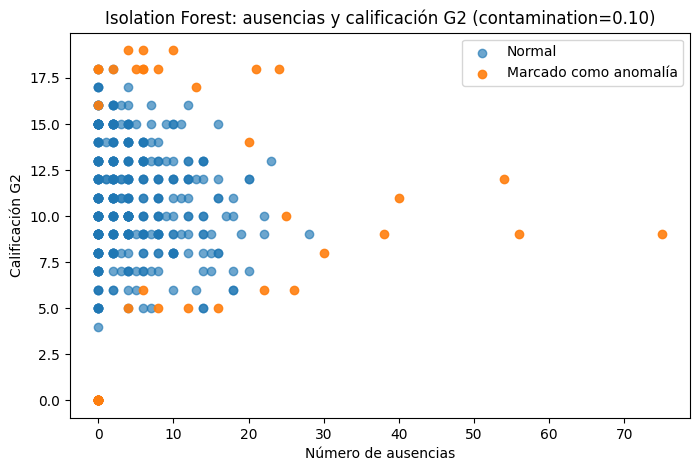

In [24]:
# Resumen comparativo entre el grupo marcado como anomalía y el grupo normal.
resumen_iforest = (
    datos_anomalias
    .assign(grupo_iforest=lambda d: np.where(d["es_anomalia_iforest_10"], "Anomalía", "Normal"))
    .groupby("grupo_iforest")
    .agg(
        estudiantes=("G2_mat", "size"),
        promedio_ausencias=("absences_mat", "mean"),
        mediana_ausencias=("absences_mat", "median"),
        promedio_G1=("G1_mat", "mean"),
        promedio_G2=("G2_mat", "mean")
    )
    .round(2)
)
print("Perfil descriptivo con contamination=0.10:")
display(resumen_iforest)

# Mostrar hasta 15 registros más aislados para revisión humana.
casos_marcados = (
    datos_anomalias.loc[
        datos_anomalias["es_anomalia_iforest_10"],
        columnas_anomalias + ["score_iforest_10"]
    ]
    .sort_values("score_iforest_10", ascending=True)
)
print("Primeros casos marcados (puntaje más bajo = más aislado):")
display(casos_marcados.head(15))

# Gráfico de dos variables; el modelo se ajustó con las tres variables seleccionadas.
plt.figure(figsize=(8, 5))
mascara_anomalia = datos_anomalias["es_anomalia_iforest_10"]
plt.scatter(
    datos_anomalias.loc[~mascara_anomalia, "absences_mat"],
    datos_anomalias.loc[~mascara_anomalia, "G2_mat"],
    label="Normal",
    alpha=0.65
)
plt.scatter(
    datos_anomalias.loc[mascara_anomalia, "absences_mat"],
    datos_anomalias.loc[mascara_anomalia, "G2_mat"],
    label="Marcado como anomalía",
    alpha=0.9
)
plt.title("Isolation Forest: ausencias y calificación G2 (contamination=0.10)")
plt.xlabel("Número de ausencias")
plt.ylabel("Calificación G2")
plt.legend()
plt.show()

### Interpretación del experimento

En la siguiente celda se comparan los tres niveles de `contamination` y se revisan los promedios de las variables entre el grupo marcado y el grupo normal. Esto ayuda a entender qué tipo de combinaciones está señalando el algoritmo.

La interpretación debe ser cuidadosa: cambiar `contamination` modifica el umbral y, por tanto, la cantidad de observaciones marcadas. Un registro señalado no debe tratarse automáticamente como error ni como evidencia de una dificultad académica; primero hay que revisar su contexto.


In [25]:
# Interpretación automática a partir de las ejecuciones de Isolation Forest
print("INTERPRETACIÓN DE LAS CONFIGURACIONES")
for _, fila in comparacion_iforest.sort_values("contamination_configurada").iterrows():
    print(
        f"- contamination={fila['contamination_configurada']:.0%}: "
        f"{int(fila['anomalias_detectadas'])} de {int(fila['estudiantes_evaluados'])} estudiantes "
        f"marcados ({fila['porcentaje_detectado']:.1f}%)."
    )

print("\nCOMPARACIÓN DE PERFILES (contamination=10%)")
if {"Anomalía", "Normal"}.issubset(set(resumen_iforest.index)):
    for variable, etiqueta in [
        ("promedio_ausencias", "ausencias promedio"),
        ("promedio_G1", "G1 promedio"),
        ("promedio_G2", "G2 promedio")
    ]:
        valor_anomalia = resumen_iforest.loc["Anomalía", variable]
        valor_normal = resumen_iforest.loc["Normal", variable]
        print(f"- {etiqueta}: anomalías={valor_anomalia:.2f}; normales={valor_normal:.2f}.")
else:
    print("No fue posible comparar ambos grupos en esta ejecución.")

print("\nLectura: las diferencias describen el comportamiento de los grupos marcados; no prueban error, causalidad ni bajo rendimiento.")


INTERPRETACIÓN DE LAS CONFIGURACIONES
- contamination=5%: 20 de 395 estudiantes marcados (5.1%).
- contamination=10%: 39 de 395 estudiantes marcados (9.9%).
- contamination=15%: 60 de 395 estudiantes marcados (15.2%).

COMPARACIÓN DE PERFILES (contamination=10%)
- ausencias promedio: anomalías=13.77; normales=4.83.
- G1 promedio: anomalías=11.44; normales=10.85.
- G2 promedio: anomalías=9.54; normales=10.84.

Lectura: las diferencias describen el comportamiento de los grupos marcados; no prueban error, causalidad ni bajo rendimiento.


### Resultados de Isolation Forest – Matemáticas

Con los 395 registros y las variables `absences_mat`, `G1_mat` y `G2_mat`, los escenarios dieron estos resultados:

| `contamination` configurada | Estudiantes marcados | Porcentaje observado |
|---:|---:|---:|
| 5 % | 20 | 5,1 % |
| 10 % | 39 | 9,9 % |
| 15 % | 60 | 15,2 % |

En el escenario de 10 %, el algoritmo marcó 39 estudiantes y dejó 356 en el grupo normal. Quienes fueron marcados tuvieron un promedio de **13,77 ausencias** (mediana de 6), G1 promedio de **11,44** y G2 promedio de **9,54**. En el grupo normal, el promedio fue de **4,83 ausencias** (mediana de 4), G1 de **10,85** y G2 de **10,84**.

En esta ejecución, las observaciones marcadas combinaron más ausencias en promedio y una nota G2 algo menor. Sin embargo, Isolation Forest no tiene una etiqueta real que indique cuáles casos son anomalías; por eso no corresponde calcular precisión o recall ni afirmar cuántos falsos positivos o falsos negativos hubo. Los registros deben revisarse uno por uno y con contexto.

*Los porcentajes observados pueden variar levemente por el redondeo. `contamination` es un parámetro del algoritmo, no una proporción real conocida de errores.*


### Ficha de limitaciones y riesgos

1. **Falsos positivos:** el algoritmo puede marcar a un estudiante por tener una combinación poco común, aunque sus datos sean correctos. Por ejemplo, podría haber una razón justificada para sus ausencias.
2. **Falsos negativos:** también puede dejar sin marcar a alguien que necesita apoyo, si sus datos se parecen a los del resto del grupo.
3. **Dependencia de `contamination`:** probé 5 %, 10 % y 15 %. Estos valores permiten comparar escenarios, pero no indican cuántas anomalías existen realmente.
4. **Variables seleccionadas:** el resultado depende de ausencias, G1 y G2. Si se incluyeran otras variables, los registros marcados podrían cambiar.
5. **No es un diagnóstico:** una anomalía no demuestra un error, fraude, falta de interés ni bajo rendimiento. Es una señal estadística que necesita revisión.
6. **Revisión humana y privacidad:** no se deben eliminar registros, etiquetar estudiantes ni tomar decisiones académicas solo con este resultado. La información debe manejarse con cuidado y cualquier seguimiento debe considerar el contexto individual.

**Decisión para este proyecto:** conservé los registros originales y agregué marcas para facilitar una revisión posterior. Utilizo Isolation Forest como apoyo exploratorio para identificar casos que vale la pena mirar con más detalle, no como una herramienta de diagnóstico o decisión definitiva.


### Registro del experimento – Matemáticas

| Elemento | Decisión tomada |
|---|---|
| Técnica | Isolation Forest (detección de anomalías) |
| Variables | `absences_mat`, `G1_mat` y `G2_mat` |
| Parámetros que se mantuvieron | `n_estimators=200`, `random_state=42` |
| Configuraciones comparadas | `contamination=0.05`, `0.10` y `0.15` |
| Resultados revisados | Cantidad y porcentaje de observaciones marcadas; perfil del escenario de 10 % |
| Uso previsto | Apoyar una revisión humana; no eliminar registros automáticamente |

Estos resultados corresponden a la ejecución independiente de Matemáticas. En el bloque posterior se repite el experimento para Portugués. Si se cambia alguno de los CSV o las variables, se deben actualizar las cifras y la interpretación.


### Detección de anomalías en el archivo de Portugués

También apliqué Isolation Forest a los registros de Portugués usando las mismas tres variables numéricas: ausencias, G1 y G2. Mantuve las tres configuraciones de `contamination` para que la comparación con Matemáticas se pueda leer de forma sencilla. Los registros marcados se conservan; no se interpretan automáticamente como errores.


Comparación de Isolation Forest – Portugués:


,contamination_configurada,registros_evaluados,anomalias_detectadas,porcentaje_observado
0,0.05,649,33,5.08
1,0.10,649,65,10.02
2,0.15,649,97,14.95


Perfil de los registros marcados y normales (contamination=10%) – Portugués:


,registros,promedio_ausencias,promedio_G1,promedio_G2
grupo_iforest_por,,,,
Anomalía,65,8.77,10.83,10.46
Normal,584,3.09,11.46,11.69


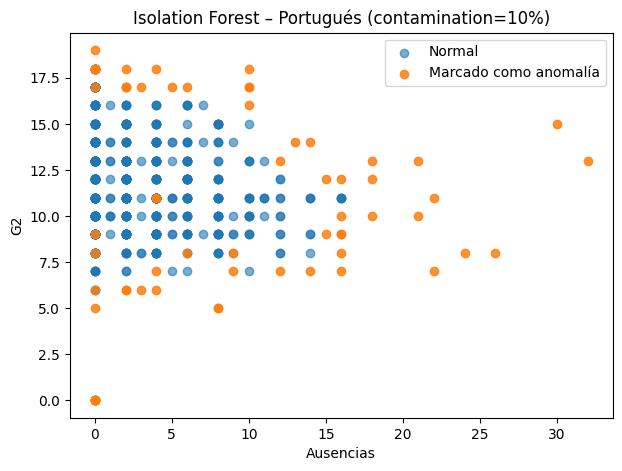

In [26]:
from sklearn.ensemble import IsolationForest

columnas_anomalias_por = ["absences_por", "G1_por", "G2_por"]
X_anomalias_por = datos_por[columnas_anomalias_por].copy()
if X_anomalias_por.isnull().any().any():
    raise ValueError("Hay nulos en las variables de Isolation Forest para Portugués.")

resultados_iforest_por = []
predicciones_iforest_por = {}
modelos_iforest_por = {}
for contamination in [0.05, 0.10, 0.15]:
    modelo_if_por = IsolationForest(
        n_estimators=200,
        contamination=contamination,
        random_state=42
    )
    etiquetas_por = modelo_if_por.fit_predict(X_anomalias_por)
    predicciones_iforest_por[contamination] = etiquetas_por
    modelos_iforest_por[contamination] = modelo_if_por
    cantidad = int((etiquetas_por == -1).sum())
    resultados_iforest_por.append({
        "contamination_configurada": contamination,
        "registros_evaluados": len(datos_por),
        "anomalias_detectadas": cantidad,
        "porcentaje_observado": cantidad / len(datos_por) * 100
    })
comparacion_iforest_por = pd.DataFrame(resultados_iforest_por)
print("Comparación de Isolation Forest – Portugués:")
display(comparacion_iforest_por.round(2))

modelo_if_por_10 = modelos_iforest_por[0.10]
datos_anomalias_por = datos_por.copy()
datos_anomalias_por["es_anomalia_iforest_10_por"] = predicciones_iforest_por[0.10] == -1
datos_anomalias_por["score_iforest_10_por"] = modelo_if_por_10.score_samples(X_anomalias_por)
datos_anomalias_por["grupo_iforest_por"] = np.where(
    datos_anomalias_por["es_anomalia_iforest_10_por"], "Anomalía", "Normal"
)
resumen_iforest_por = datos_anomalias_por.groupby("grupo_iforest_por").agg(
    registros=("G2_por", "size"),
    promedio_ausencias=("absences_por", "mean"),
    promedio_G1=("G1_por", "mean"),
    promedio_G2=("G2_por", "mean")
).round(2)
print("Perfil de los registros marcados y normales (contamination=10%) – Portugués:")
display(resumen_iforest_por)

plt.figure(figsize=(7, 5))
mascara_por = datos_anomalias_por["es_anomalia_iforest_10_por"]
plt.scatter(datos_anomalias_por.loc[~mascara_por, "absences_por"], datos_anomalias_por.loc[~mascara_por, "G2_por"], label="Normal", alpha=0.6)
plt.scatter(datos_anomalias_por.loc[mascara_por, "absences_por"], datos_anomalias_por.loc[mascara_por, "G2_por"], label="Marcado como anomalía", alpha=0.85)
plt.title("Isolation Forest – Portugués (contamination=10%)")
plt.xlabel("Ausencias")
plt.ylabel("G2")
plt.legend()
plt.show()


### Lectura de Isolation Forest en Portugués

En Portugués, Isolation Forest marcó **33 registros con `contamination=5 %`, 65 con `10 %` y 97 con `15 %`**. Para revisar los casos, tomé el escenario intermedio del 10 %. Los 65 registros marcados tuvieron un promedio de 8,77 ausencias, frente a 3,09 en el grupo no marcado. Sus promedios de G1 y G2 también fueron algo menores.

Esto muestra que el algoritmo está encontrando combinaciones menos habituales dentro de la base. No significa que esos registros estén mal ni que todos correspondan a estudiantes con dificultades. La decisión correcta es conservarlos y revisar cada caso con información adicional.

# Proyecto final integrado –
En esta parte reúno los resultados de Matemáticas y Portugués para mostrar qué patrones aparecen en cada archivo y qué diferencias se observan entre las dos asignaturas. Los datos se procesaron por separado; por eso, la comparación es general y no supone que cada registro de un archivo corresponda a la misma persona del otro.

## Producto analítico final: tablero comparativo

El tablero integra los resultados principales de calidad y EDA, segmentación, clasificación y detección de anomalías. La idea es que una persona que no haya seguido las clases pueda entender qué se analizó, cuáles fueron los resultados más importantes y qué precauciones hay que tener al interpretarlos.


In [27]:
# Tablero integrado: comparación de las dos asignaturas

silhouette_mat = float(comparacion_k.loc[comparacion_k["k"] == k_elegido, "silhouette"].iloc[0])
silhouette_por = float(comparacion_k_por.loc[comparacion_k_por["k"] == k_elegido_por, "silhouette"].iloc[0])

anomalias_mat_10 = int(comparacion_iforest.loc[comparacion_iforest["contamination_configurada"] == 0.10, "anomalias_detectadas"].iloc[0])
anomalias_por_10 = int(comparacion_iforest_por.loc[comparacion_iforest_por["contamination_configurada"] == 0.10, "anomalias_detectadas"].iloc[0])
pct_anomalias_mat_10 = anomalias_mat_10 / len(datos) * 100
pct_anomalias_por_10 = anomalias_por_10 / len(datos_por) * 100

indicadores_finales = pd.DataFrame([
    ["Registros analizados", len(datos), len(datos_por)],
    ["Promedio de G3", round(datos["G3_mat"].mean(), 2), round(datos_por["G3_por"].mean(), 2)],
    ["Bajo rendimiento (G3 < 10)", f"{y.mean()*100:.2f}%", f"{y_por.mean()*100:.2f}%"],
    ["Promedio de ausencias", round(datos["absences_mat"].mean(), 2), round(datos_por["absences_por"].mean(), 2)],
    ["K-means: k seleccionado", k_elegido, k_elegido_por],
    ["K-means: Silhouette", round(silhouette_mat, 3), round(silhouette_por, 3)],
    ["Árbol: accuracy de prueba", round(accuracy_test, 3), round(accuracy_test_por, 3)],
    ["Árbol: F1 de bajo rendimiento", round(f1, 3), round(f1_por, 3)],
    ["Isolation Forest (10%): anomalías", f"{anomalias_mat_10} ({pct_anomalias_mat_10:.1f}%)", f"{anomalias_por_10} ({pct_anomalias_por_10:.1f}%)"]
], columns=["Indicador", "Matemáticas", "Portugués"])

print("RESUMEN COMPARATIVO DE LAS DOS BASES")
display(indicadores_finales)
print("Las cifras son comparaciones generales entre dos archivos independientes; no representan emparejamientos persona a persona.")


RESUMEN COMPARATIVO DE LAS DOS BASES


,Indicador,Matemáticas,Portugués
0,Registros analizados,395,649
1,Promedio de G3,10.42,11.91
2,Bajo rendimiento (G3 < 10),32.91%,15.41%
3,Promedio de ausencias,5.71,3.66
4,K-means: k seleccionado,4,3
5,K-means: Silhouette,0.417,0.396
6,Árbol: accuracy de prueba,0.908,0.938
7,Árbol: F1 de bajo rendimiento,0.867,0.786
8,Isolation Forest (10%): anomalías,39 (9.9%),65 (10.0%)


Las cifras son comparaciones generales entre dos archivos independientes; no representan emparejamientos persona a persona.


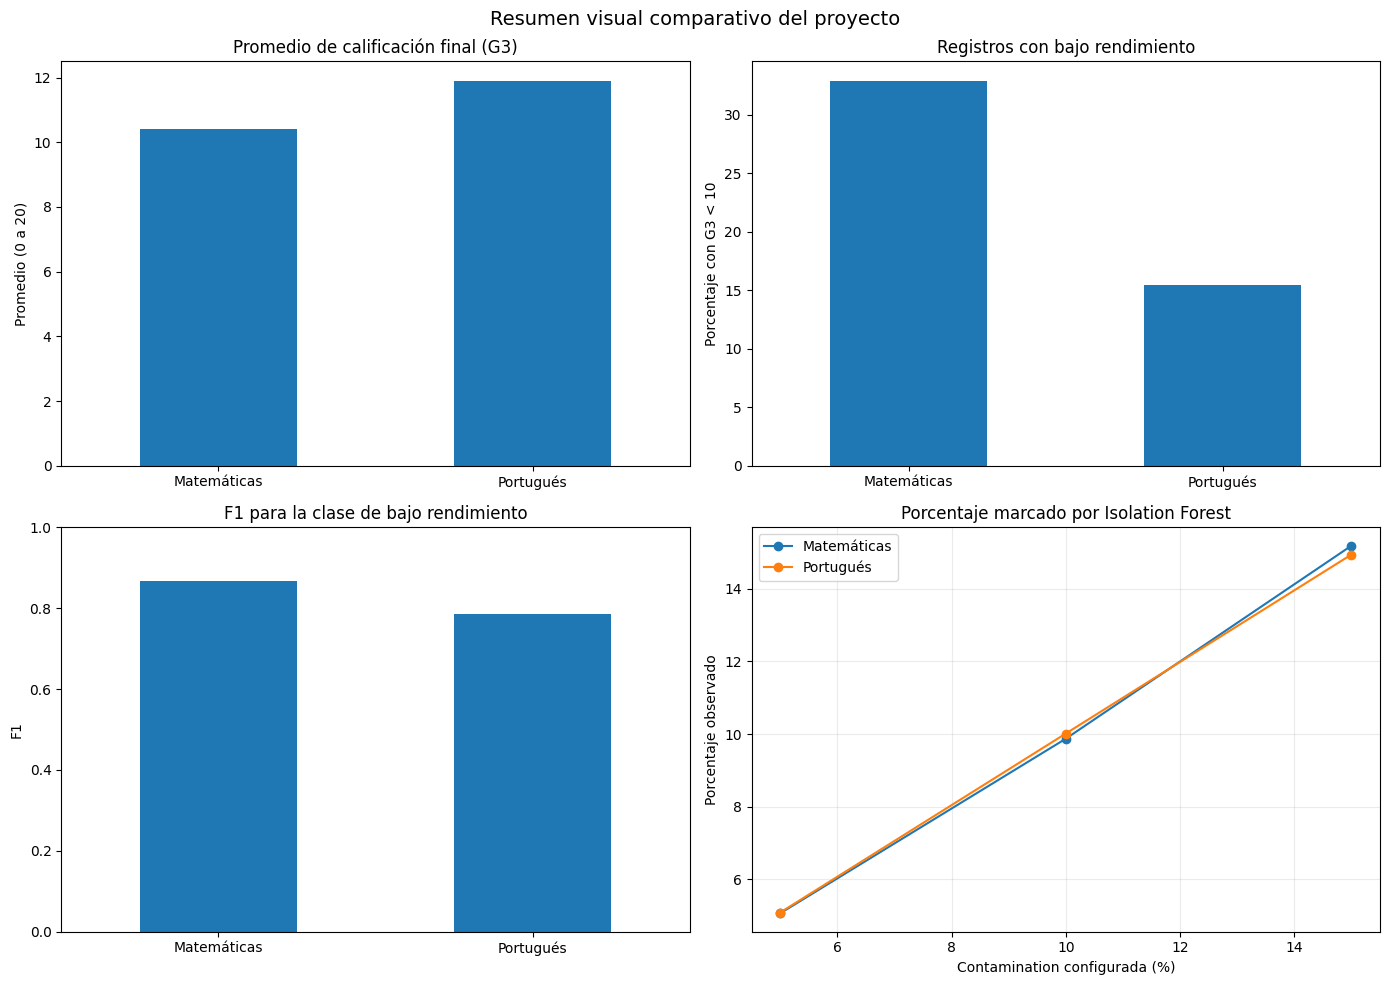

In [28]:
# Vista integrada: hallazgos principales de Matemáticas y Portugués
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Promedio de calificación final.
pd.Series({"Matemáticas": datos["G3_mat"].mean(), "Portugués": datos_por["G3_por"].mean()}).plot(kind="bar", ax=axes[0, 0])
axes[0, 0].set_title("Promedio de calificación final (G3)")
axes[0, 0].set_ylabel("Promedio (0 a 20)")
axes[0, 0].tick_params(axis="x", rotation=0)

# 2. Proporción de bajo rendimiento.
pd.Series({"Matemáticas": y.mean()*100, "Portugués": y_por.mean()*100}).plot(kind="bar", ax=axes[0, 1])
axes[0, 1].set_title("Registros con bajo rendimiento")
axes[0, 1].set_ylabel("Porcentaje con G3 < 10")
axes[0, 1].tick_params(axis="x", rotation=0)

# 3. F1 de los dos árboles.
pd.Series({"Matemáticas": f1, "Portugués": f1_por}).plot(kind="bar", ax=axes[1, 0])
axes[1, 0].set_title("F1 para la clase de bajo rendimiento")
axes[1, 0].set_ylabel("F1")
axes[1, 0].set_ylim(0, 1)
axes[1, 0].tick_params(axis="x", rotation=0)

# 4. Porcentaje marcado por Isolation Forest en los tres escenarios.
iforest_comp = pd.DataFrame({
    "contamination (%)": [5, 10, 15],
    "Matemáticas": comparacion_iforest["porcentaje_detectado"].values,
    "Portugués": comparacion_iforest_por["porcentaje_observado"].values
}).set_index("contamination (%)")
iforest_comp.plot(marker="o", ax=axes[1, 1])
axes[1, 1].set_title("Porcentaje marcado por Isolation Forest")
axes[1, 1].set_ylabel("Porcentaje observado")
axes[1, 1].set_xlabel("Contamination configurada (%)")
axes[1, 1].grid(alpha=0.25)

plt.suptitle("Resumen visual comparativo del proyecto", fontsize=14)
plt.tight_layout()
plt.show()


## recorrido de las unidades 1 a 8


**Alcance de la comparación:** los dos archivos comparten variables, pero sus tamaños son distintos y no contienen una llave personal común. Por eso comparo promedios, porcentajes y métricas por asignatura; no afirmo que los registros estén emparejados ni que las diferencias sean causadas por la materia.

**Reproducibilidad:** para repetir el proyecto se necesitan los dos CSV y ejecutar las celdas desde el principio. Se mantienen semillas aleatorias (`random_state=42`) en los modelos que las utilizan. Si cambia alguno de los archivos, deben actualizarse las métricas, los gráficos y las interpretaciones.


## Cierre del proyecto

Al desarrollar este trabajo entendí que aplicar algoritmos no es suficiente para resolver un problema. También fue necesario revisar si los datos realmente respondían a la pregunta inicial, comparar resultados y reconocer cuándo una técnica puede equivocarse.

El cambio del enfoque inicial hacia rendimiento académico fue una decisión basada en las variables disponibles, no un intento de forzar el dataset para responder algo que no mide. Desde mi formación en Ingeniería de Software, considero importante que una solución analítica sea reproducible, pero también que sus resultados se puedan explicar y usar con responsabilidad.

Como siguiente paso, sería conveniente probar el modelo con datos de otro periodo o institución y conversar con docentes para validar si las señales encontradas tienen sentido en la práctica. Por ahora, el proyecto funciona como un ejercicio de análisis y apoyo exploratorio, no como una herramienta para decidir automáticamente sobre la trayectoria de un estudiante.




In [29]:
# Interpretación integrada de los resultados de las dos asignaturas
cluster_riesgo_mat = resumen_clusters["porcentaje_bajo_rendimiento"].idxmax()
cluster_riesgo_por = resumen_clusters_por["porcentaje_bajo_rendimiento"].idxmax()
fn_mat = int(falsos_negativos)
fp_mat = int(falsos_positivos)
fn_por = int(matriz_por[1, 0])
fp_por = int(matriz_por[0, 1])

print("RESUMEN INTEGRADO DE RESULTADOS")
print(
    f"\nEn Matemáticas, el cluster {cluster_riesgo_mat} presenta la mayor proporción de bajo rendimiento "
    f"({resumen_clusters.loc[cluster_riesgo_mat, 'porcentaje_bajo_rendimiento']:.1f}%). "
    f"En Portugués, el cluster {cluster_riesgo_por} tiene la mayor proporción "
    f"({resumen_clusters_por.loc[cluster_riesgo_por, 'porcentaje_bajo_rendimiento']:.1f}%)."
)
print(
    f"\nEl árbol de Matemáticas dejó {fn_mat} falsos negativos y generó {fp_mat} falsas alarmas; "
    f"el árbol de Portugués dejó {fn_por} falsos negativos y generó {fp_por} falsas alarmas. "
    "Por eso no conviene usar ninguna predicción como decisión automática."
)
print(
    f"\nCon contamination=10%, Isolation Forest marcó {anomalias_mat_10} de {len(datos)} registros "
    f"de Matemáticas y {anomalias_por_10} de {len(datos_por)} de Portugués. "
    "Las marcas señalan observaciones poco comunes para el algoritmo, no errores confirmados."
)
print(
    "\nEn conjunto, los dos archivos muestran patrones distintos y sirven para practicar un análisis comparable. "
    "Como no se pueden emparejar registros entre asignaturas, las diferencias se interpretan a nivel de cada muestra. "
    "Los resultados pueden orientar una revisión docente, pero no prueban causalidad ni reemplazan el contexto de cada estudiante."
)


RESUMEN INTEGRADO DE RESULTADOS

En Matemáticas, el cluster 2 presenta la mayor proporción de bajo rendimiento (67.2%). En Portugués, el cluster 2 tiene la mayor proporción (29.4%).

El árbol de Matemáticas dejó 3 falsos negativos y generó 8 falsas alarmas; el árbol de Portugués dejó 8 falsos negativos y generó 4 falsas alarmas. Por eso no conviene usar ninguna predicción como decisión automática.

Con contamination=10%, Isolation Forest marcó 39 de 395 registros de Matemáticas y 65 de 649 de Portugués. Las marcas señalan observaciones poco comunes para el algoritmo, no errores confirmados.

En conjunto, los dos archivos muestran patrones distintos y sirven para practicar un análisis comparable. Como no se pueden emparejar registros entre asignaturas, las diferencias se interpretan a nivel de cada muestra. Los resultados pueden orientar una revisión docente, pero no prueban causalidad ni reemplazan el contexto de cada estudiante.
